# Data, Inference, and Applied Machine Learning - Assignment 6

In [1]:
# Importation of libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, KFold, TimeSeriesSplit, cross_validate, cross_val_score
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, mean_squared_error, r2_score

# Fix the random seed for reproducability
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110

## Setup and data

The analysis is based on a single daily dataset covering six East African cities: Kigali, Nairobi, Kampala, Dodoma, Bujumbura and Dar es Salaam. Each observation represents one city on one day. The file is loaded from the project GitHub link; where that link is unavailable, the copy stored alongside the notebook is used.

The dataset contains 9,144 observations, comprising 1,524 days per city from 29 July 2022 to 29 September 2026. Air pollution measurements are missing for the first six days of each city (36 observations). Those observations are retained for Questions 2 and 3, which require only meteorological variables, and are excluded from Question 4, which requires the pollution variables.

In [2]:
# Load the daily file and I put the rows in city and date order
data_url = "https://raw.githubusercontent.com/api-sage/diaml_projects/refs/heads/main/project6/east_africa_weather_airquality_daily.csv"
try:
    df = pd.read_csv(data_url, parse_dates=["date"])
except Exception:
    df = pd.read_csv("east_africa_weather_airquality_daily.csv", parse_dates=["date"])
df = df.sort_values(["city", "date"]).reset_index(drop=True)

# Name the groups of columns once so later cells stay short
weather_vars = ["temp_mean", "temp_max", "temp_min", "humidity_mean", "dew_point_mean",
                "pressure_mean", "cloud_cover_mean", "wind_speed_mean", "radiation_mean",
                "precipitation_sum"]
pollutant_vars = ["co", "no2", "so2", "o3", "aod", "dust"]
predictors_16 = weather_vars + pollutant_vars
cities = ["Bujumbura", "Dar es Salaam", "Dodoma", "Kampala", "Kigali", "Nairobi"]

# Show the first rows and a short summary of the file
display(df.head())
summary = pd.DataFrame({
    "item": ["rows", "cities", "first date", "last date", "days per city", "rows with no pm2_5"],
    "value": [len(df), df["city"].nunique(), str(df["date"].min().date()), str(df["date"].max().date()),
              len(df) // df["city"].nunique(), int(df["pm2_5"].isna().sum())]
})
display(summary)

,city,date,temp_mean,temp_max,temp_min,humidity_mean,dew_point_mean,pressure_mean,cloud_cover_mean,wind_speed_mean,...,precipitation_sum,pm2_5,pm10,co,no2,so2,o3,aod,dust,rain_tomorrow
0,Bujumbura,2022-07-29,23.225000,28.1,19.5,67.625000,16.654167,925.608333,54.708333,9.704167,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,Bujumbura,2022-07-30,23.366667,28.0,20.2,66.875000,16.508333,925.929167,55.500000,9.437500,...,2.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,Bujumbura,2022-07-31,23.570833,28.3,19.7,70.333333,17.479167,925.775000,48.708333,9.483333,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,Bujumbura,2022-08-01,23.408333,28.8,19.6,68.958333,16.975000,926.333333,53.208333,8.041667,...,7.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,Bujumbura,2022-08-02,22.750000,26.2,19.8,71.250000,17.020833,925.604167,81.750000,9.629167,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


,item,value
0,rows,9144
1,cities,6
2,first date,2022-07-29
3,last date,2026-09-29
4,days per city,1524
5,rows with no pm2_5,36


### Question 1 - Nonlinearity

#### 1.1 Can you explain what nonlinearity is and why it might be necessary to consider nonlinear relationships between variables?

Nonlinearity denotes a relationship between variables that cannot adequately be represented by a single straight line. Under a linear relationship, a unit increase in the predictor produces a constant change in the response, irrespective of the starting value. Under a nonlinear relationship, the magnitude of that change depends on the level of the predictor: the relationship may accelerate, saturate, remain flat before rising sharply beyond a threshold, or increase and subsequently decrease.

Rainfall provides an illustration. A modest increase in humidity on an already dry day may leave the probability of rain largely unchanged, whereas the same increase beyond high levels of humidity and cloud cover can raise that probability substantially. The initial and final increments therefore do not exert equivalent effects, and a linear specification provides a poor description of the process.

Three considerations motivate explicit allowance for nonlinearity. First, fitting a linear model to a curved relationship yields biased predictions, with systematic patterns remaining in the residuals. Second, inference may be misleading: a symmetric rise and fall relationship can produce a slope close to zero despite a strong underlying association. Third, many processes are nonlinear by construction, including growth towards a limit, dose response relationships that saturate, and rainfall formation that requires moisture to exceed a threshold.

Accordingly, exploratory plots and residual diagnostics require examination, and linear specifications require comparison against flexible alternatives on held out data. A nonlinear form is warranted where it produces a material reduction in out of sample error.

#### 1.2 Write down the mathematical equation for a nonlinear model and provide an example of an application where it might be appropriate.

A general nonlinear model is written as

$$y_i = f(x_i; \theta) + \varepsilon_i,$$

where $y_i$ denotes the response for observation $i$, $x_i$ denotes the predictors, $\theta$ denotes the unknown parameters to be estimated from the data, $f$ is a nonlinear function, and $\varepsilon_i$ is the error term. The defining property is that at least one parameter enters $f$ nonlinearly, for example within an exponent or a ratio, so that the model cannot be re-expressed as a weighted sum of known terms.

A representative form is the saturating growth curve

$$y = a\left(1 - e^{-bx}\right) + \varepsilon, \qquad a > 0, \; b > 0,$$

where $a$ is the asymptotic level approached by $y$ and $b$ governs the rate of approach. Because $b$ appears inside the exponential term, the model is nonlinear in its parameters. A polynomial specification such as $y = \beta_0 + \beta_1 x + \beta_2 x^2 + \varepsilon$ is curved in $x$ yet remains linear in its parameters, and is therefore classified as a linear model with a transformed predictor rather than a nonlinear model in the present sense.

An appropriate application is the relationship between drug dose and pharmacological effect. At very low doses the effect is negligible; as dose increases the effect rises steeply; beyond a high dose the effect plateaus at a physiological maximum. A linear specification would increase without bound and would eventually predict effects exceeding that maximum. The saturating curve, by contrast, originates at zero and approaches $a$ asymptotically, so that each parameter retains a direct interpretation.

#### 1.3 Can a nonlinear model be more parsimonious than a linear model? Write down mathematical formulae for both the linear and nonlinear models to support your answer.

A nonlinear model can indeed be more parsimonious than a linear model. Parsimony is understood here as the attainment of an adequate fit with few estimated parameters, such that each parameter contributes materially to the specification.

Consider a true relationship that rises rapidly at first and subsequently flattens towards an upper level, as in Question 1.2. A specification that is linear in its parameters must approximate that curvature through polynomial terms:

$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \beta_4 x^4 + \beta_5 x^5 + \varepsilon.$$

Six parameters are required, and additional terms may be necessary where the curvature is pronounced or the range of $x$ is wide. The fitted curve may nevertheless oscillate towards the extremes of the range, and the individual $\beta$ coefficients admit no straightforward interpretation in isolation.

The nonlinear specification for the same shape is

$$y = a\left(1 - e^{-bx}\right) + \varepsilon,$$

which contains only two parameters, the asymptote $a$ and the rate $b$. The correct functional shape is thereby obtained across the full range, the parameters correspond to identifiable features of the process, and the risk of overfitting is reduced because fewer parameters are available to accommodate sampling noise.

Linearity in the parameters therefore does not guarantee simplicity. Where the underlying shape corresponds to a known nonlinear form, the nonlinear specification constitutes the more parsimonious choice. Empirical comparison on held out data remains advisable, since a parsimonious specification is advantageous only where its assumed shape approximates the data generating process.

#### 1.4 Surrogate data are used for testing for nonlinearity. What characteristics are typically preserved when generating surrogates? Give the names of two surrogate techniques and describe the approaches for implementing them.

Surrogate data provide a reference framework for assessing whether an apparently nonlinear pattern could have arisen from a linear process. A large ensemble of artificial series is generated so that the linear properties of the observed series are retained while nonlinear structure is destroyed. A nonlinear statistic computed on the observed series is then compared with its distribution across the surrogates: a value outside the surrogate range constitutes evidence of nonlinearity, whereas a value within that range provides no such evidence.

The characteristics conventionally preserved are the series length and sampling interval, the mean and variance, the power spectrum (equivalently, the autocorrelation structure), and, in refined methods, the marginal distribution of the observations. The null hypothesis under test depends on the construction. Phase randomisation tests a linear Gaussian process, while amplitude adjusted methods test the wider null of a linear process observed through a static nonlinear measurement function.

The first technique is phase randomisation, also termed Fourier transform surrogates. The Fourier transform decomposes the series into components characterised by amplitudes and phases. The amplitudes are retained exactly and the phases are replaced by random values drawn subject to the symmetry required for a real valued series, after which the inverse transform is applied. Preservation of the amplitudes guarantees an identical power spectrum and autocorrelation structure, while randomisation of the phases destroys the phase coupling in which nonlinear dependence resides. The resulting values are approximately Gaussian.

The second technique is the iterated amplitude adjusted Fourier transform (IAAFT). Iteration commences from a shuffled copy of the series, so that the marginal distribution is exact at the outset. Two operations are then alternated: the original power spectrum is imposed by substituting the original amplitudes in the Fourier domain, and the original distribution is imposed by rank ordering, whereby the current values are replaced by the sorted original values of corresponding rank. After sufficient iterations both properties are approximated closely. The simpler AAFT procedure applies the two operations once, with a correspondingly less exact spectral match.

In application, an ensemble of, for example, 99 surrogates is generated and the selected nonlinear statistic, such as a local prediction error, is evaluated on the observed series and on each surrogate. Location of the observed value outside the surrogate range leads to rejection of the linear null at approximately the 1 percent level.

#### 1.5 Define information, entropy, and mutual information, and also provide mathematical formulas. Describe how entropy can be used for constructing a feature for measuring regularity and give an example of an application. Explain how mutual information can be used for feature selection and why it might be better than correlation.

The information content of an event is inversely related to its probability: rare events convey more information than common events. For an outcome $x$ with probability $p(x)$, information is defined as

$$I(x) = -\log_2 p(x).$$

With logarithms to base 2 the unit is the bit. An outcome of probability one half carries 1 bit, while an outcome of probability one eighth carries 3 bits.

Entropy is the expected information of a random variable. For a discrete variable $X$,

$$H(X) = -\sum_x p(x) \log_2 p(x).$$

Entropy approaches zero where one outcome is almost certain, since the next value occasions little surprise, and is maximised where outcomes are equiprobable. Related quantities are the joint entropy $H(X, Y)$ and the conditional entropy $H(X \mid Y) = H(X, Y) - H(Y)$, representing the uncertainty remaining in $X$ after observation of $Y$.

Mutual information quantifies the reduction in uncertainty about one variable afforded by knowledge of another, and is equivalently expressed as

$$I(X; Y) = \sum_{x, y} p(x, y) \log_2 \frac{p(x, y)}{p(x)\, p(y)} = H(X) - H(X \mid Y).$$

The measure is zero if and only if $X$ and $Y$ are independent, increases with the strength of dependence of arbitrary form, and is symmetric in its arguments.

An entropy based feature for regularity is constructed by partitioning a signal into short windows and evaluating an entropy measure within each window. Regular, repetitive behaviour yields low entropy because subsequent values are highly predictable, whereas irregular behaviour yields high entropy. Established variants include sample entropy, based on the persistence of matched patterns under extension by one observation, and permutation entropy, based on the ordinal patterns of short subsequences. A representative application is the monitoring of interbeat intervals derived from an electrocardiogram. Cardiac strain is frequently accompanied by more stereotyped beating, reflected in falling entropy; such a decline may therefore flag patients requiring closer assessment before changes in mean interval become apparent.

For feature selection, each candidate predictor is scored by its mutual information with the target, and highly scoring predictors are retained. Mutual information is preferable to correlation where nonlinear dependence is suspected, because correlation detects only linear association. In the case $Y = X^2$ with $X$ distributed symmetrically about zero, correlation is approximately zero and a correlation screen discards $X$, although $X$ determines $Y$ up to sign and mutual information is substantially positive. The same advantage applies to threshold relationships, where the response changes only beyond a critical predictor value. Two limitations require acknowledgement: probability estimation by binning or nearest neighbours renders mutual information sensitive to those choices and more data demanding than correlation, and univariate scoring disregards redundancy, so that retained predictors may duplicate information and require subsequent redundancy checks.

### Question 2 - Classification using trees (25 points)

#### 2.1. Decision trees are often used to transform a set of observations into a specific recommended action. Describe the components (nodes, branches) of a decision tree. What is pruning, and why might it be necessary to prune the tree? Why are decision trees an attractive method for classification in practical applications?

A decision tree converts a set of observations on a case into a specific recommended action through a sequence of binary questions. The structure is conventionally drawn with the root at the top.

The root node contains all training observations and poses the first, most informative question, for example whether precipitation on the current day is at most 0.55 mm. Every node that poses a question is an internal node; each test concerns a single variable against a single threshold. The lines emanating from a node are its branches, typically two per node, corresponding to the affirmative and negative outcomes, with each branch carrying the subset of observations producing that outcome. Successive partitioning yields progressively smaller and purer subsets, in the sense that one class increasingly predominates. Terminal boxes are leaf nodes, which pose no further question and deliver the classification, such as rain or no rain, commonly accompanied by the class proportions observed in that leaf during training. An operational action is then attached to each leaf, for example issuance or withholding of a rain alert. The depth of the tree is the length of the longest root to leaf path.

Pruning denotes the removal of branches, with a node thereby converted into a leaf, even at some cost to training fit. Pruning is necessary because an unrestricted tree continues to split until leaves contain very few observations, at which point idiosyncratic features of the training sample, such as a single unusual storm, are effectively memorised and generalisation to new observations deteriorates. An excessively large tree is additionally difficult to interpret, to translate into action, and may be unstable under minor perturbations of the data. Pruning may be imposed during growth through a maximum depth or a minimum leaf size, or applied retrospectively through cost complexity pruning, in which a penalty parameter, conventionally denoted alpha, regulates the trade off between fit and tree size.

Decision trees remain attractive for classification in applied settings for several reasons. The rule sequence leading to any classification can be inspected and explained to decision makers, which supports trust and accountability. No scaling of predictors is required, nonlinear and threshold effects are accommodated without explicit specification, data preparation demands are modest, and a ranking of predictor importance is obtained as a by product. The principal limitation is instability: modest changes in the data may alter the upper splits. Pruning and evaluation on unseen data are the standard safeguards against that risk.

#### 2.2. Suppose an organization has built a rule-based classifier using domain knowledge. After collecting a large amount of data, outline the steps required to improve upon the existing approach by constructing a data-driven classifier. How would you advise testing the validity of the new model?

The existing rule based classifier is treated as the benchmark to be improved upon, and its specification is held fixed while the data driven alternative is developed. The recommended procedure is as follows.

The prediction task is first defined precisely: the constitution of a positive case, the information available at the time of decision, and the relative costs of the two error types. A clean analytical dataset is then assembled by linking historical inputs to known outcomes, using the fields available to the rules together with any additional fields now collected. Erroneous records are corrected or flagged, and fields that would leak the outcome, for example fields completed only after the outcome is known, are excluded. The data are subsequently partitioned into training, tuning and final test subsets; where observations are ordered in time, later observations are reserved for testing so that evaluation reproduces operational conditions. A data driven classifier is fitted on the training subset and its hyperparameters tuned on the tuning subset. Comparison with the rule system is conducted on identical locked test cases using operationally relevant criteria, including accuracy, ROC AUC and error costs. Cases in which the rules outperform the model are then examined: some will reflect data defects requiring correction, while others may identify domains in which expert rules retain value and should be retained as a fallback. Deployment proceeds through a shadow period, in which predictions are recorded without being acted upon, followed by phased introduction with monitoring for drift.

With respect to validity, the final test subset must remain untouched until the model and all tuning decisions are finalised, so that the reported performance remains unbiased. Uncertainty intervals should accompany point estimates. Performance requires examination within important subgroups, such as individual sites or seasons, together with calibration assessment where decisions depend on predicted probabilities. A particularly stringent check is evaluation on a later time period or a new site excluded from development. A model that prevails only on data used in its construction does not warrant confidence.

#### 2.3. Use the daily weather data for six East African cities (Kigali, Nairobi, Kampala, Dodoma, Bujumbura and Dar es Salaam) provided on Canvas. The target variable is rain_tomorrow, which is 1 if more than 1 mm of rain falls on the next day and 0 otherwise. Report the proportion of days with rain tomorrow in each city. Which city has the highest and which the lowest share of rainy days? Test whether the differences between cities could be due to chance. (Use a chi-square test of independence between city and rain_tomorrow.)

,no_rain_days,rain_days,total_days,rain_share
city,,,,
Kampala,605,919,1524,0.6030
Dar es Salaam,766,758,1524,0.4974
Kigali,876,648,1524,0.4252
Nairobi,905,619,1524,0.4062
Bujumbura,1002,522,1524,0.3425
Dodoma,1196,328,1524,0.2152


,item,value
0,chi-square statistic,5.492000e+02
1,degrees of freedom,5.000000e+00
2,p-value,1.905528e-116
3,smallest expected count,6.323000e+02


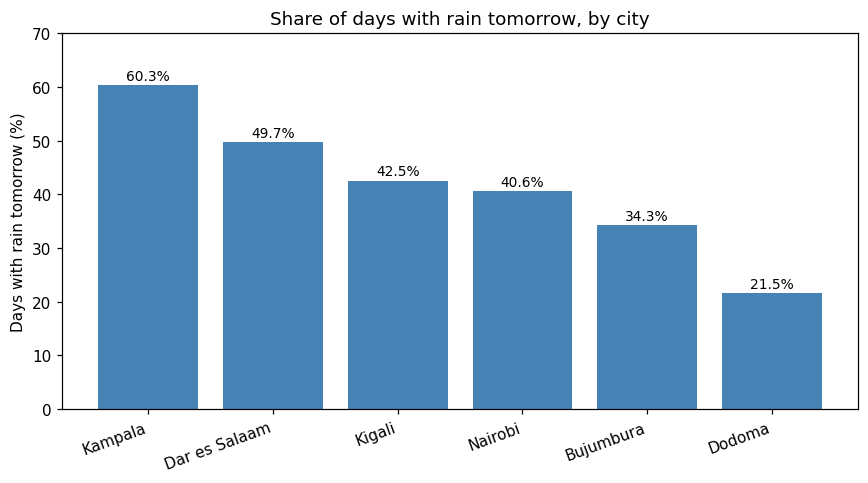

In [3]:
# Count dry days and rainy days for each city and work out the rainy share
counts = pd.crosstab(df["city"], df["rain_tomorrow"], margins=False)
counts.columns = ["no_rain_days", "rain_days"]
counts["total_days"] = counts["no_rain_days"] + counts["rain_days"]
counts["rain_share"] = counts["rain_days"] / counts["total_days"]
counts = counts.reindex(cities).sort_values("rain_share", ascending=False)
display(counts.round(4))

# Test if city and rain tomorrow look independent or linked
chi2_stat, p_value, dof, expected = chi2_contingency(pd.crosstab(df["city"], df["rain_tomorrow"]))
test_result = pd.DataFrame({
    "item": ["chi-square statistic", "degrees of freedom", "p-value", "smallest expected count"],
    "value": [round(chi2_stat, 2), dof, p_value, round(expected.min(), 1)]
})
display(test_result)

# Draw the rainy share for each city so the gap is easy to see
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(counts.index, counts["rain_share"] * 100, color="steelblue")
ax.set_ylabel("Days with rain tomorrow (%)")
ax.set_title("Share of days with rain tomorrow, by city")
ax.set_ylim(0, 70)
for i, v in enumerate(counts["rain_share"] * 100):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

The tabulated proportions and the figure support the same conclusion. Kampala records the highest share of days followed by rain, at 60.3 percent (919 of 1,524 days). Dar es Salaam follows at 49.7 percent, then Kigali at 42.5 percent, Nairobi at 40.6 percent and Bujumbura at 34.3 percent. Dodoma records the lowest share, at 21.5 percent (328 days). The difference between the wettest and driest cities approaches 39 percentage points, a substantial gap given the sample sizes involved. Because each city contributes exactly 1,524 days, the proportions are directly comparable. Across the six cities combined, 41.5 percent of days are followed by rain.

The chi-square test evaluates whether differences of this magnitude are compatible with independence between city and rain_tomorrow. The test statistic is 549.20 on 5 degrees of freedom, with a p-value far below 0.001. The smallest expected cell count under independence is approximately 632, comfortably exceeding values at which the approximation becomes unreliable. The differences between cities are therefore interpreted as genuine rather than attributable to sampling variation. The ordering is also geographically coherent: Kampala lies within the moist Lake Victoria basin, whereas Dodoma occupies a considerably drier inland zone.

#### 2.4. Pool the observations from all six cities and, using today's ten weather variables as predictors (temp_mean, temp_max, temp_min, humidity_mean, dew_point_mean, pressure_mean, cloud_cover_mean, wind_speed_mean, radiation_mean and precipitation_sum), construct a decision tree to classify rain_tomorrow and display the structure of the tree using a graphic.

,item,value
0,depth of full tree,30
1,leaves in full tree,1623
2,days used,9144
3,predictors used,10


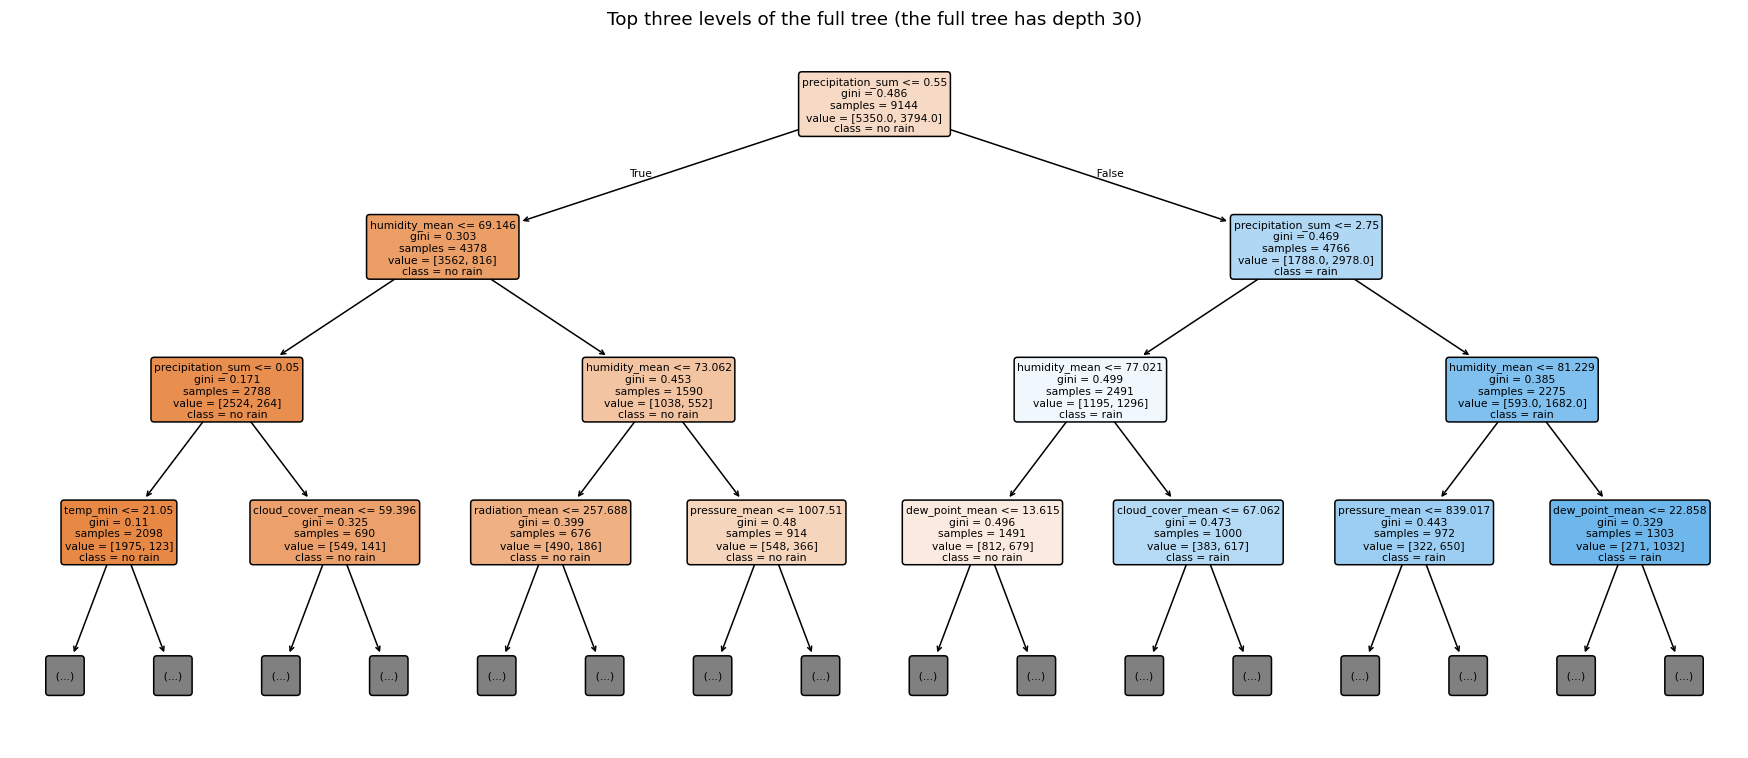

In [4]:
# Pool all cities and fit a tree with no size limit first
X_all = df[weather_vars]
y_all = df["rain_tomorrow"]

full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
full_tree.fit(X_all, y_all)

size_table = pd.DataFrame({
    "item": ["depth of full tree", "leaves in full tree", "days used", "predictors used"],
    "value": [full_tree.get_depth(), full_tree.get_n_leaves(), len(df), len(weather_vars)]
})
display(size_table)

# The full tree is far too big to read, so I draw only its top three levels
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(full_tree, max_depth=3, feature_names=weather_vars,
          class_names=["no rain", "rain"], filled=True, rounded=True, fontsize=7, ax=ax)
ax.set_title("Top three levels of the full tree (the full tree has depth 30)")
plt.tight_layout()
plt.show()

The initial tree was fitted without any size constraint to all 9,144 pooled observations. The resulting structure attains depth 30 with 1,623 leaves, a scale that indicates memorisation of fine detail in the training data and precludes interpretation as an operational rule set. The figure therefore displays only the first three levels, which contain the substantively important partitions.

The root partition is defined by precipitation on the current day: observations with precipitation_sum at most 0.55 mm are separated from wetter observations. This ordering is consistent with the temporal clustering of rainfall, whereby a wet day elevates the probability of rain on the following day. Subsequent partitions involve humidity_mean, again consistent with the requirement of moist air for continued rain formation. One path may be read as follows: observations characterised by precipitation above 0.55 mm together with high humidity terminate predominantly in rain leaves, whereas dry observations with low humidity terminate in no rain leaves. The several hundred partitions below this level largely accommodate noise rather than signal, a difficulty addressed through pruning in the following section.

#### 2.5. Evaluate the performance of the tree before and after pruning, using 10-fold cross-validation. Prune the tree either by limiting its depth or using cost-complexity pruning, and choose the pruning strength (maximum depth or alpha) by cross-validation.

,max_depth,accuracy,roc_auc,train_roc_auc
0,1,0.7103,0.7214,0.7253
1,2,0.7130,0.7765,0.7831
2,3,0.7192,0.7919,0.8008
3,4,0.7261,0.7965,0.8109
4,5,0.7255,0.7969,0.8227
5,6,0.7215,0.7952,0.8356
6,8,0.7128,0.7741,0.8722
7,10,0.7025,0.7378,0.9166
8,no limit,0.6570,0.6473,1.0000


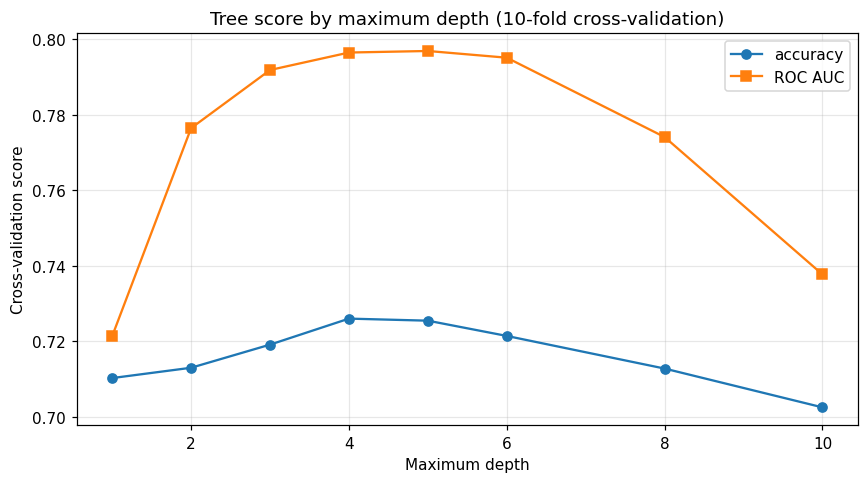

In [5]:
# Score each tree size with 10-fold cross-validation and I keep the train score to show overfitting
cv_class = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

depth_list = [1, 2, 3, 4, 5, 6, 8, 10]
depth_rows = []
for depth in depth_list:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    scores = cross_validate(tree, X_all, y_all, cv=cv_class,
                            scoring=["accuracy", "roc_auc"], return_train_score=True)
    depth_rows.append({"max_depth": depth,
                       "accuracy": scores["test_accuracy"].mean(),
                       "roc_auc": scores["test_roc_auc"].mean(),
                       "train_roc_auc": scores["train_roc_auc"].mean()})

# Add the full tree as the before pruning case
scores_full = cross_validate(DecisionTreeClassifier(random_state=RANDOM_STATE),
                             X_all, y_all, cv=cv_class,
                             scoring=["accuracy", "roc_auc"], return_train_score=True)
depth_rows.append({"max_depth": "no limit",
                   "accuracy": scores_full["test_accuracy"].mean(),
                   "roc_auc": scores_full["test_roc_auc"].mean(),
                   "train_roc_auc": scores_full["train_roc_auc"].mean()})
depth_table = pd.DataFrame(depth_rows)
display(depth_table.round(4))

# Draw accuracy and ROC AUC against depth
plot_rows = depth_table[depth_table["max_depth"] != "no limit"].copy()
plot_rows["max_depth"] = plot_rows["max_depth"].astype(int)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(plot_rows["max_depth"], plot_rows["accuracy"], marker="o", label="accuracy")
ax.plot(plot_rows["max_depth"], plot_rows["roc_auc"], marker="s", label="ROC AUC")
ax.set_xlabel("Maximum depth")
ax.set_ylabel("Cross-validation score")
ax.set_title("Tree score by maximum depth (10-fold cross-validation)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,alpha,accuracy,roc_auc
0,0.0000,0.6570,0.6473
1,0.0005,0.7242,0.7930
2,0.0010,0.7287,0.7949
3,0.0015,0.7250,0.7925
4,0.0020,0.7216,0.7880
5,0.0030,0.7187,0.7834
6,0.0050,0.7130,0.7765
7,0.0100,0.7130,0.7742


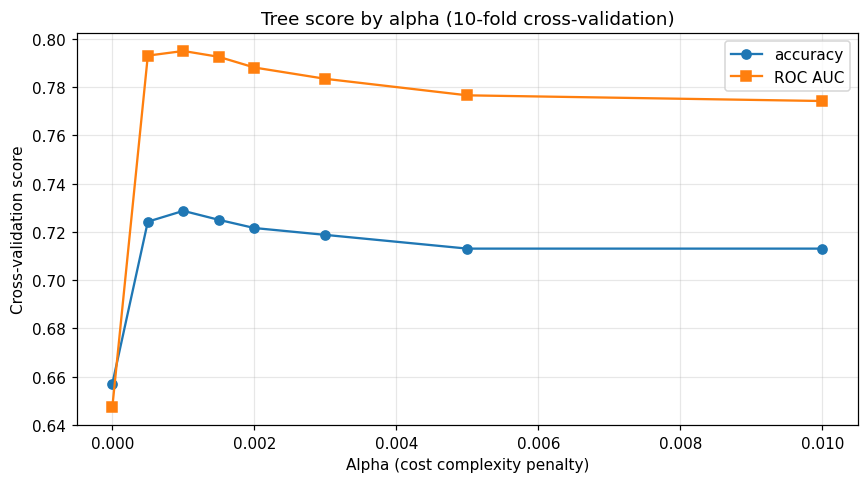

,item,value
0,depth of final tree,4
1,leaves in final tree,16


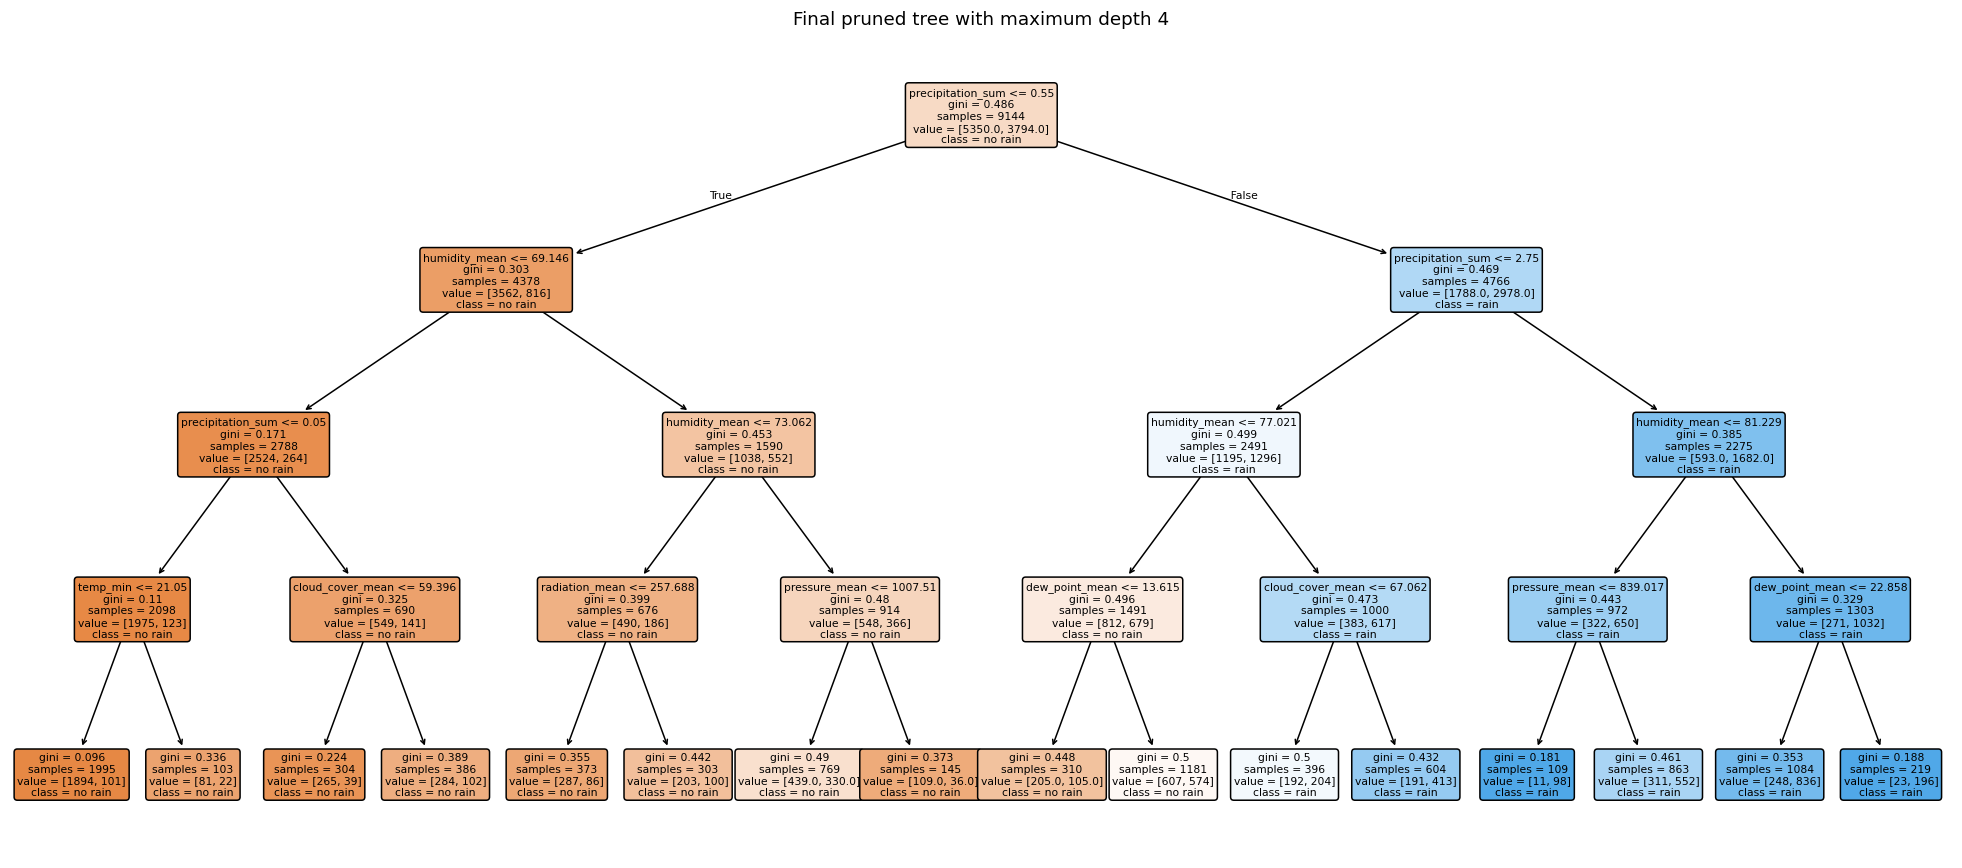

In [6]:
# Also try cost complexity pruning so I can compare the two pruning styles
alpha_list = [0.0, 0.0005, 0.001, 0.0015, 0.002, 0.003, 0.005, 0.01]
alpha_rows = []
for alpha in alpha_list:
    tree = DecisionTreeClassifier(ccp_alpha=alpha, random_state=RANDOM_STATE)
    scores = cross_validate(tree, X_all, y_all, cv=cv_class, scoring=["accuracy", "roc_auc"])
    alpha_rows.append({"alpha": alpha,
                       "accuracy": scores["test_accuracy"].mean(),
                       "roc_auc": scores["test_roc_auc"].mean()})
alpha_table = pd.DataFrame(alpha_rows)
display(alpha_table.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(alpha_table["alpha"], alpha_table["accuracy"], marker="o", label="accuracy")
ax.plot(alpha_table["alpha"], alpha_table["roc_auc"], marker="s", label="ROC AUC")
ax.set_xlabel("Alpha (cost complexity penalty)")
ax.set_ylabel("Cross-validation score")
ax.set_title("Tree score by alpha (10-fold cross-validation)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Fix the final tree at depth 4 and I draw it in full
final_tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
final_tree.fit(X_all, y_all)
final_size = pd.DataFrame({
    "item": ["depth of final tree", "leaves in final tree"],
    "value": [final_tree.get_depth(), final_tree.get_n_leaves()]
})
display(final_size)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(final_tree, feature_names=weather_vars, class_names=["no rain", "rain"],
          filled=True, rounded=True, fontsize=7, ax=ax)
ax.set_title("Final pruned tree with maximum depth 4")
plt.tight_layout()
plt.show()

Prior to pruning, the unrestricted tree attains cross-validated accuracy of 0.657 and ROC AUC of 0.647, against a training ROC AUC of 1.0. The discrepancy between training and cross-validated performance constitutes clear evidence of overfitting: the tree reproduces the training observations almost exactly while generalising poorly. For reference, a trivial rule predicting no rain on every day would achieve accuracy of 0.585, since 58.5 percent of days remain dry; the unrestricted tree improves on that benchmark only modestly under honest evaluation.

Pruning produces a marked improvement. ROC AUC rises to approximately 0.777 at maximum depth 2, 0.792 at depth 3, and 0.797 at depth 4, where accuracy is 0.726. Performance at depth 5 is essentially equivalent (ROC AUC 0.797) and deteriorates thereafter as memorisation resumes. Cost complexity pruning corroborates this pattern: the best value examined, alpha equal to 0.001, yields accuracy of 0.729 and ROC AUC of 0.795, close to the depth limited result. Given the agreement between the two approaches, the depth constraint is adopted on grounds of transparency and ease of representation.

The final tree has depth 4 and 16 leaves. Pruning thus reduces the number of leaves from 1,623 to 16 while simultaneously increasing accuracy by approximately 7 percentage points and ROC AUC by approximately 15 percentage points. In substantive terms, a near perfect fit to historical observations is exchanged for a compact rule set that retains its performance on new observations. Inspection of the final structure confirms that every path commencing with a dry day terminates in a no rain leaf, and that rain classifications arise only following a wet day accompanied by high humidity.

#### 2.6. Compare the performance of the final tree with logistic regression using accuracy and ROC AUC, and comment on the advantages and disadvantages of both. Which weather variables does the tree rely on most? Which model would you use for a daily rain classification, and why?

,model,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Final tree (depth 4),0.7261,0.0150,0.7965,0.0147
1,Logistic regression,0.7337,0.0205,0.8104,0.0161


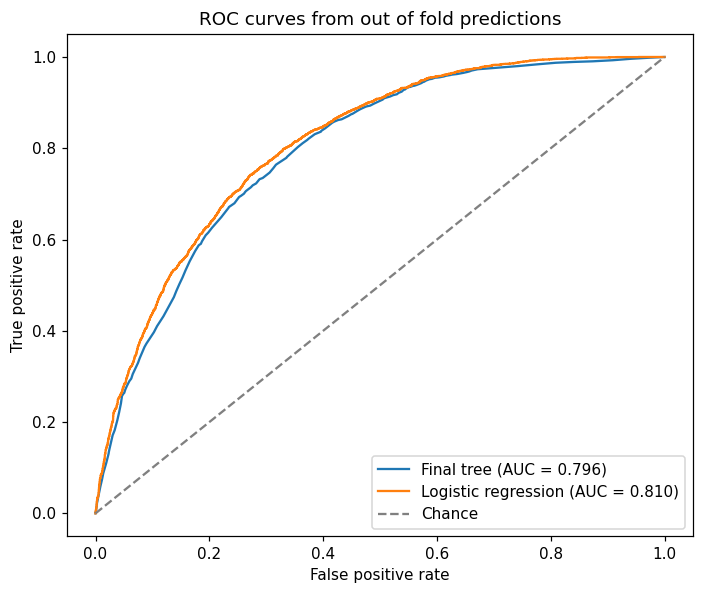

,variable,importance
0,temp_mean,0.0000
1,temp_max,0.0000
7,wind_speed_mean,0.0000
8,radiation_mean,0.0026
2,temp_min,0.0041
4,dew_point_mean,0.0128
6,cloud_cover_mean,0.0157
5,pressure_mean,0.0166
3,humidity_mean,0.1494
9,precipitation_sum,0.7989


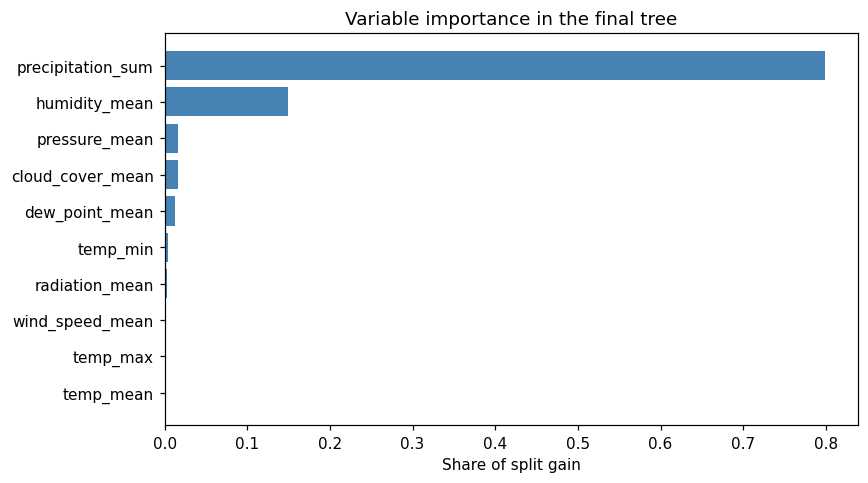

In [7]:
# Compare the final tree with logistic regression on the same folds
logreg = Pipeline([("scaler", StandardScaler()),
                   ("model", LogisticRegression(max_iter=1000))])
models = {"Final tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
          "Logistic regression": logreg}
compare_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_all, y_all, cv=cv_class, scoring=["accuracy", "roc_auc"])
    compare_rows.append({"model": name,
                         "accuracy_mean": scores["test_accuracy"].mean(),
                         "accuracy_std": scores["test_accuracy"].std(),
                         "roc_auc_mean": scores["test_roc_auc"].mean(),
                         "roc_auc_std": scores["test_roc_auc"].std()})
compare_table = pd.DataFrame(compare_rows)
display(compare_table.round(4))

# Collect out of fold chances from both models and I draw the two ROC curves
prob_tree = np.zeros(len(df))
prob_logreg = np.zeros(len(df))
for train_idx, test_idx in cv_class.split(X_all, y_all):
    tree_fold = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
    tree_fold.fit(X_all.iloc[train_idx], y_all.iloc[train_idx])
    prob_tree[test_idx] = tree_fold.predict_proba(X_all.iloc[test_idx])[:, 1]
    logreg_fold = Pipeline([("scaler", StandardScaler()),
                            ("model", LogisticRegression(max_iter=1000))])
    logreg_fold.fit(X_all.iloc[train_idx], y_all.iloc[train_idx])
    prob_logreg[test_idx] = logreg_fold.predict_proba(X_all.iloc[test_idx])[:, 1]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for probs, label in [(prob_tree, "Final tree"), (prob_logreg, "Logistic regression")]:
    fpr, tpr, _ = roc_curve(y_all, probs)
    ax.plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(y_all, probs):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves from out of fold predictions")
ax.legend()
plt.tight_layout()
plt.show()

# Show how much the final tree leans on each weather variable
importance = pd.DataFrame({"variable": weather_vars,
                           "importance": final_tree.feature_importances_}).sort_values("importance", ascending=True)
display(importance.round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance["variable"], importance["importance"], color="steelblue")
ax.set_xlabel("Share of split gain")
ax.set_title("Variable importance in the final tree")
plt.tight_layout()
plt.show()

Logistic regression performs marginally better on both criteria, attaining accuracy of 0.734 and ROC AUC of 0.810, compared with 0.726 and 0.797 for the final tree. The difference is small relative to the fold to fold standard deviation of approximately 0.015 and is accordingly interpreted as a slight rather than decisive advantage. The ROC curves display the same pattern, with the logistic curve lying slightly above the tree curve over most thresholds. Both models substantially exceed the trivial no rain benchmark of 0.585, confirming that genuine predictive signal is present. The out of fold AUC values shown in the figure agree with the cross-validated estimates, supporting the reliability of the comparison.

Variable importance within the final tree is dominated by precipitation_sum, which accounts for approximately 0.80 of the total reduction in impurity, followed by humidity_mean at approximately 0.15. All remaining variables contribute less than 0.02 each, and temp_mean, temp_max and wind_speed_mean contribute zero. This does not imply that the remaining variables are devoid of information; rather, conditional on precipitation and humidity, their additional partitions do not survive pruning. The tree essentially encodes a persistence mechanism, whereby wet and moist conditions tend to continue.

The relative merits of the two approaches may be summarised as follows. The tree supplies inspectable rules that can be printed and operationalised directly, requires no scaling, and identifies thresholds automatically; against this, its predictions change discontinuously at threshold values, the structure may prove unstable under data shifts, and small but systematic effects that fail to win a partition are discarded. Logistic regression supplies smooth predicted probabilities, distributes weight across all ten predictors, and ranks observations somewhat more accurately; against this, scaling is required, the decision boundary is linear in the scaled predictors unless nonlinear terms are introduced explicitly, and coefficients are less directly translatable into field rules than tree paths.

For daily rain classification, logistic regression is the preferred model. Operational deployment requires a probability rather than a categorical pronouncement, so that alert thresholds can be set according to the relative costs of missed rain events and false alarms. Logistic regression offers the superior ranking and smoother probabilities at no cost in accuracy. The pruned tree remains valuable as an interpretable account of why wet, humid days attract high scores.

### Question 3 - Classification using KNN: will it rain tomorrow?

#### 3.1 By focusing on small neighborhoods of state space, it is possible to construct parsimonious models. Describe the concept behind this general approach and a step-by-step procedure for implementing such a model.

The underlying principle is that observations with similar states tend to be followed by similar outcomes. Each day is represented as a point in a state space whose coordinates are the meteorological measurements for that day, including temperature, humidity and current precipitation. A neighbourhood consists of the historical days whose points lie close to the point representing a new day. Rather than estimating a single global equation, prediction is based on the outcomes of those neighbouring historical days. The approach is parsimonious in that few global parameters are estimated: the principal choices are the definition of closeness and the number of neighbours admitted. The stored dataset itself substitutes for an extensive set of fitted coefficients.

Implementation proceeds through the following steps. A state vector is first constructed for each day from variables available at forecast time. Predictors are placed on comparable scales and a distance measure is selected, since proximity is meaningless where one coordinate is recorded in hundreds and another in single digits. The neighbourhood size $k$ is selected by cross-validation rather than by judgement. For a new day, the $k$ nearest historical days are retrieved. Their outcomes are then combined: classification proceeds by majority vote, with the vote share providing an approximate probability, while regression proceeds by averaging. Performance is finally evaluated on observations excluded from the neighbour store construction process, and $k$, the scaling and the distance measure are revised until held out performance ceases to improve.

Two trade offs govern these choices. Very small neighbourhoods capture local detail but are sensitive to noise, since a single atypical day can reverse a classification. Large neighbourhoods are stable but may obscure genuine local structure, for example where coastal regimes are diluted by inland observations. Dimensionality also warrants care, because distances become less discriminative as coordinates are added.

#### 3.2 Consider the challenge of predicting whether it will rain tomorrow, using today's weather as predictors. To construct a KNN classifier, how will you transform the available variables?

The six cities are pooled and the same ten meteorological predictors employed in Question 2 are retained, ensuring comparability between the KNN and tree results. City is not introduced as a predictor, in accordance with the formulation of the task in terms of current weather. All ten predictors are continuous, so no dummy encoding is required; the meteorological fields are complete, so no imputation rule is necessary; and the target, rain_tomorrow, is excluded from the predictor set.

The principal transformation is standardisation to z-scores: each variable is centred on its mean and divided by its standard deviation, giving mean zero and unit variance. Critically, the centring and scaling constants are estimated within training folds only and then applied to the corresponding test fold; estimation on the full dataset would leak test information into training. The necessity of this step is evident from the ranges tabulated below. Pressure and radiation are recorded in hundreds, humidity in tens, and precipitation predominantly between zero and a few units. On raw scales, Euclidean type distances would be dominated by pressure and radiation, while humidity and precipitation, the latter being the strongest signal identified by the tree, would exert negligible influence.

Two further features are noted. Precipitation is strongly skewed, with many zeros and a long upper tail, so that very wet days remain distant from the bulk of observations even after standardisation; a logarithmic type compression would constitute a reasonable variant, but the raw scale is retained so that the predictor set remains identical to that of Question 2. In addition, the three temperature variables are mutually correlated, with the consequence that thermal information is effectively counted repeatedly in distance calculations. All three are retained for comparability, although removal of redundancy would be a legitimate means of reducing the dimensionality of the state space.

In [8]:
# Show the range of each weather variable to explain why scaling is needed
scale_table = df[weather_vars].agg(["min", "max", "mean", "std"]).T
scale_table = scale_table.rename(columns={"std": "standard_deviation"})
display(scale_table.round(2))

,min,max,mean,standard_deviation
temp_mean,14.81,29.53,22.31,2.61
temp_max,18.20,36.20,27.52,2.31
temp_min,9.10,27.60,18.02,3.35
humidity_mean,30.29,96.04,71.36,11.05
dew_point_mean,3.02,25.23,16.20,3.83
pressure_mean,835.09,1013.54,900.62,55.00
cloud_cover_mean,0.00,100.00,65.53,25.65
wind_speed_mean,2.27,26.42,9.69,4.61
radiation_mean,43.96,336.92,241.55,41.39
precipitation_sum,0.00,63.50,2.54,4.74


#### 3.3 Calculate the performance of the classifier versus the number of neighbors used and provide a graphic to display the result. What is the optimal number of neighbors based on ROC AUC using cross-validation of 10 folds?

,k,accuracy,roc_auc,roc_auc_std
0,1,0.6699,0.6600,0.0136
1,3,0.7037,0.7477,0.0136
2,5,0.7147,0.7722,0.0121
3,7,0.7205,0.7848,0.0142
4,9,0.7208,0.7905,0.0139
5,11,0.7259,0.7973,0.0131
6,15,0.7274,0.8036,0.0127
7,21,0.7263,0.8060,0.0120
8,31,0.7278,0.8093,0.0129
9,41,0.7282,0.8113,0.0126


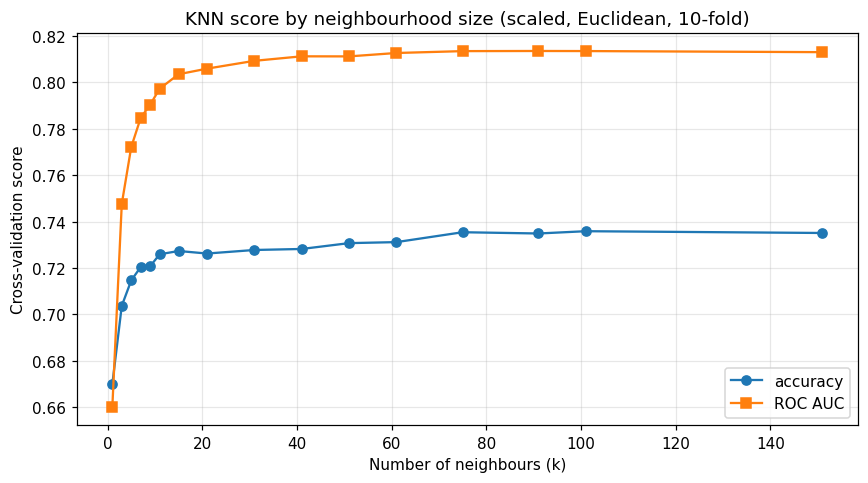

In [9]:
# Try many neighbourhood sizes with scaled inputs and Euclidean distance
cv_class = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
k_list = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 61, 75, 91, 101, 151]
k_rows = []
for k in k_list:
    knn = Pipeline([("scaler", StandardScaler()),
                    ("model", KNeighborsClassifier(n_neighbors=k))])
    scores = cross_validate(knn, X_all, y_all, cv=cv_class, scoring=["accuracy", "roc_auc"])
    k_rows.append({"k": k,
                   "accuracy": scores["test_accuracy"].mean(),
                   "roc_auc": scores["test_roc_auc"].mean(),
                   "roc_auc_std": scores["test_roc_auc"].std()})
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))

# Draw both scores against the neighbourhood size
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_table["k"], k_table["accuracy"], marker="o", label="accuracy")
ax.plot(k_table["k"], k_table["roc_auc"], marker="s", label="ROC AUC")
ax.set_xlabel("Number of neighbours (k)")
ax.set_ylabel("Cross-validation score")
ax.set_title("KNN score by neighbourhood size (scaled, Euclidean, 10-fold)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The resulting curve displays the expected behaviour of a local method. With a single neighbour, ROC AUC is only approximately 0.66, because classification rests on one historical day and is consequently unstable. Performance improves rapidly as neighbours are added, exceeding 0.79 at $k = 9$ and 0.80 at $k = 15$, after which gains diminish and the curve settles onto a broad plateau. The maximum is attained at $k = 91$, with ROC AUC of 0.814 and accuracy of 0.735; $k = 75$ and $k = 101$ lie within 0.001 of that value, and the entire range from approximately $k = 51$ to $k = 151$ falls within the fold to fold variability. The optimum is therefore interpreted as a region rather than a precise point.

On the ROC AUC criterion, the optimal neighbourhood size is accordingly $k = 91$ under standardisation with Euclidean distance, subject to the qualification that any value within the plateau performs comparably. The breadth of the optimum indicates insensitivity to the precise choice. Accuracy follows the same trajectory, rising from 0.67 at $k = 1$ to approximately 0.735 on the plateau. Substantively, a single day of weather constitutes a noisy guide, whereas aggregation over dozens of comparable historical days stabilises classification without erasing local structure. The distance measure is refined in the following section, and that search determines the final KNN specification retained thereafter.

#### 3.4 Explain why some distance metrics are sensitive to the kind of features used. Evaluate the performance using 4 different distance metrics (e.g., Euclidean, Manhattan, and Chebyshev, and cosine), with and without standardizing the predictors.

A distance is an aggregate over features, so the units and dispersion of each feature determine its weight within that aggregate. Euclidean distance squares each coordinate difference before summation, with the result that a variable recorded in large units, such as pressure in hundreds, can dominate a variable recorded in small units, such as precipitation in single digits, even where the latter carries the predictive signal. Manhattan distance aggregates absolute differences and is therefore less dominated by any single large discrepancy, although a 50 unit pressure difference still outweighs a 2 unit precipitation difference on raw scales. Chebyshev distance retains only the largest coordinate difference, so classification may hinge entirely on the variable with the widest raw range. Cosine distance compares the direction, or profile, of two vectors and disregards their overall magnitude, yet on raw scales the angle remains oriented towards the large unit axes. Standardisation expresses each feature in units of its own dispersion, restoring an initially equal contribution. Scaling is therefore expected to benefit the first three measures substantially, and cosine distance to a lesser but still appreciable extent.

In the evaluation that follows, the task is held constant and only the metric and the scaling are varied. For each of the eight combinations the same $k$ grid is searched and the combination is represented by its best $k$ on ROC AUC, so that every metric is assessed under its most favourable configuration.

,scaled,metric,best_k,accuracy,roc_auc
1,yes,manhattan,101,0.7388,0.8157
0,yes,euclidean,101,0.7359,0.8135
3,yes,cosine,75,0.7318,0.8109
2,yes,chebyshev,101,0.7349,0.8097
5,no,manhattan,51,0.7305,0.8072
4,no,euclidean,51,0.7200,0.7971
7,no,cosine,51,0.7201,0.7940
6,no,chebyshev,31,0.7123,0.7883


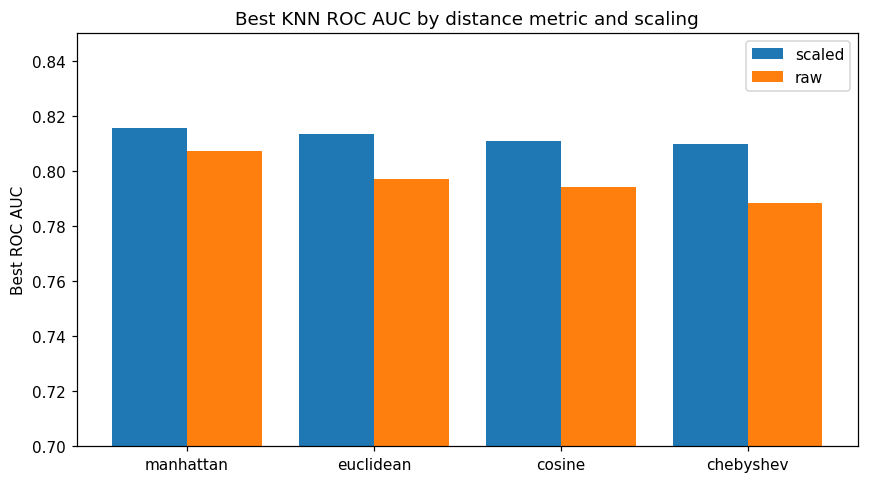

In [10]:
# Compare four distance rules with and without scaling, each at its best k
metric_grid = {"euclidean": {"metric": "euclidean"},
               "manhattan": {"metric": "manhattan"},
               "chebyshev": {"metric": "chebyshev"},
               "cosine": {"metric": "cosine"}}
k_short = [5, 11, 21, 31, 51, 75, 101]
metric_rows = []
for scaled in [True, False]:
    for metric_name, metric_args in metric_grid.items():
        best = None
        for k in k_short:
            steps = []
            if scaled:
                steps.append(("scaler", StandardScaler()))
            steps.append(("model", KNeighborsClassifier(n_neighbors=k, **metric_args)))
            scores = cross_validate(Pipeline(steps), X_all, y_all, cv=cv_class,
                                    scoring=["accuracy", "roc_auc"])
            auc = scores["test_roc_auc"].mean()
            if best is None or auc > best["roc_auc"]:
                best = {"scaled": "yes" if scaled else "no", "metric": metric_name, "best_k": k,
                        "accuracy": scores["test_accuracy"].mean(), "roc_auc": auc}
        metric_rows.append(best)
metric_table = pd.DataFrame(metric_rows).sort_values("roc_auc", ascending=False)
display(metric_table.round(4))

# Draw ROC AUC for each metric with and without scaling
pivot = metric_table.pivot(index="metric", columns="scaled", values="roc_auc").reindex(
    ["manhattan", "euclidean", "cosine", "chebyshev"])
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(pivot))
ax.bar(x - 0.2, pivot["yes"], width=0.4, label="scaled")
ax.bar(x + 0.2, pivot["no"], width=0.4, label="raw")
ax.set_xticks(x)
ax.set_xticklabels(pivot.index)
ax.set_ylabel("Best ROC AUC")
ax.set_title("Best KNN ROC AUC by distance metric and scaling")
ax.set_ylim(0.7, 0.85)
ax.legend()
plt.tight_layout()
plt.show()

Standardisation improves every metric, confirming that raw units distort the geometry of proximity. The strongest combination overall is Manhattan distance with standardisation, at ROC AUC of 0.816, with standardised Euclidean distance close behind at 0.813. Standardised cosine distance follows, and Chebyshev distance trails the group, consistent with its reliance on a single coordinate. Without standardisation, Manhattan distance again leads its group, at approximately 0.807, because absolute differences are less vulnerable than squared differences to the very large pressure discrepancies that penalise Euclidean distance. Unstandardised Chebyshev distance is weakest, at approximately 0.789.

Two conclusions follow. First, the decision to standardise is more consequential than the choice among the leading metrics: the advantage of Manhattan over Euclidean under standardisation is minimal, whereas the gain from standardisation itself is pronounced for Chebyshev, cosine and Euclidean distances. Second, the Manhattan result admits a substantive explanation. Meteorological differences are frequently concentrated in one coordinate, such as an abrupt precipitation increase, and a sum of absolute differences is less distorted by a single extreme coordinate than a sum of squares. Manhattan distance with standardisation, at its optimal $k = 101$, is therefore adopted as the final KNN specification; standardised Euclidean distance would perform in a closely comparable manner.

#### 3.5 Compare the best KNN classifier with the final decision tree from Question 2 using accuracy and ROC AUC, and comment on the advantages and disadvantages of KNN.

,model,accuracy,roc_auc
0,"Best KNN (Manhattan, k=101)",0.7388,0.8157
1,Final tree (depth 4),0.7261,0.7965


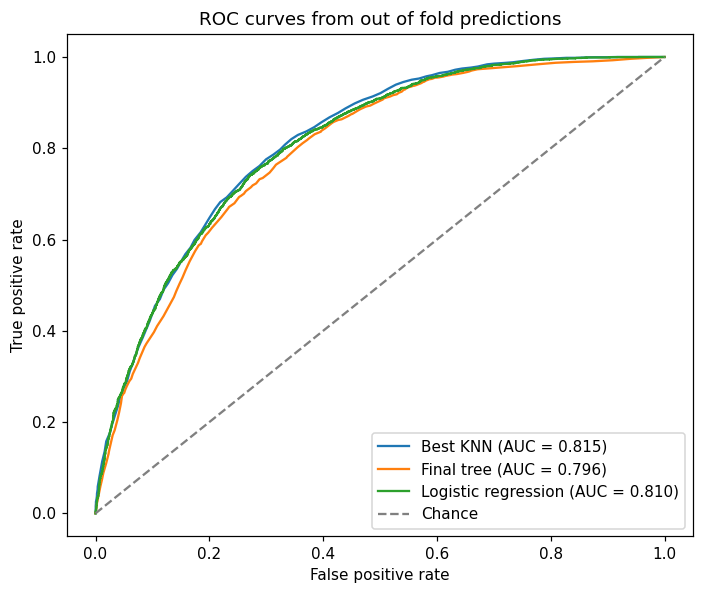

In [11]:
# Compare my best KNN with the final tree on the same folds
best_knn = Pipeline([("scaler", StandardScaler()),
                     ("model", KNeighborsClassifier(n_neighbors=101, metric="manhattan"))])
knn_tree_rows = []
for name, model in {"Best KNN (Manhattan, k=101)": best_knn,
                    "Final tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)}.items():
    scores = cross_validate(model, X_all, y_all, cv=cv_class, scoring=["accuracy", "roc_auc"])
    knn_tree_rows.append({"model": name,
                          "accuracy": scores["test_accuracy"].mean(),
                          "roc_auc": scores["test_roc_auc"].mean()})
display(pd.DataFrame(knn_tree_rows).round(4))

# Draw the ROC curves from out of fold predictions for both models
prob_knn = np.zeros(len(df))
for train_idx, test_idx in cv_class.split(X_all, y_all):
    fold_model = Pipeline([("scaler", StandardScaler()),
                           ("model", KNeighborsClassifier(n_neighbors=101, metric="manhattan"))])
    fold_model.fit(X_all.iloc[train_idx], y_all.iloc[train_idx])
    prob_knn[test_idx] = fold_model.predict_proba(X_all.iloc[test_idx])[:, 1]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for probs, label in [(prob_knn, "Best KNN"), (prob_tree, "Final tree"), (prob_logreg, "Logistic regression")]:
    fpr, tpr, _ = roc_curve(y_all, probs)
    ax.plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(y_all, probs):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves from out of fold predictions")
ax.legend()
plt.tight_layout()
plt.show()

The best KNN specification outperforms the final tree on both criteria, with accuracy of 0.739 against 0.726 and ROC AUC of 0.816 against 0.797. The ROC curves place KNN close to logistic regression and clearly above the tree. The advantage is nevertheless modest, at approximately two AUC points, and is interpreted as superior ranking rather than a difference in kind. All three models occupy a narrow performance band, suggesting that the ten meteorological variables contain a limited quantity of next day signal, most of which is recovered by each method.

The advantages of KNN are that no functional form for the decision boundary is imposed, so that curved and threshold patterns are accommodated automatically; all ten variables contribute smoothly; and incorporation of new observations updates the model immediately without refitting. The disadvantages are equally clear. Standardised inputs and retention of the historical dataset are required, every prediction entails a search through that store, and both $k$ and the distance measure demand careful tuning. No compact rule set is produced: the neighbouring days supporting a classification can be exhibited, but no short rule list comparable to a tree path can be supplied to operational staff. The method also degrades as dimensionality increases, since the distinction between near and distant observations weakens, although with ten predictors performance remains strong. In summary, KNN is assessed as the stronger pure scoring instrument for the pooled task, while the tree remains preferable where an explicit account of each classification is required.

#### 3.6 The data are consecutive days. Explain why random cross-validation might overestimate performance when forecasting future rainfall. Suggest an alternative validation approach. Which model would you use for a daily rain forecast, and why?

Random cross-validation shuffles observations before partitioning, so the training set contains days immediately adjacent in time to each test day. Meteorological conditions persist in spells extending over several days. Where a wet spell runs from Monday to Friday, a shuffled partition may place Monday and Friday in training and Wednesday in testing; the model is then credited with recognising a spell that has effectively been partially observed, a materially easier task than anticipating a new spell in a future month. Precipitation on the current day, the strongest predictor, aggravates this leakage because its test values are closely replicated in neighbouring training days. Pooling six cities introduces a further channel: the same seasons and synoptic systems appear on both sides of the partition. The resulting estimates flatter the models relative to the operational task, in which every forecast concerns genuinely future days.

The appropriate alternative is validation in temporal order. Observations within each city are sorted by date and test blocks are always drawn from a later period than training blocks. Suitable designs include forward chaining, in which the training window expands as the test block advances, and a single terminal holdout, such as the final fifth of each city record, reserved until development is complete. Tuning is likewise confined to the earlier period, so that no future observation influences any modelling choice, and a short gap between training and test segments assists in breaking spell overlap. Both checks are implemented below: a time series split applied to the pooled record, and a terminal block holdout estimated separately for each city.

In [12]:
# Recheck the three models with splits that respect time order
time_cv = TimeSeriesSplit(n_splits=5)
pool_sorted = df.sort_values("date").reset_index(drop=True)
X_time = pool_sorted[weather_vars]
y_time = pool_sorted["rain_tomorrow"]
time_models = {"Best KNN (Manhattan, k=101)": Pipeline([("scaler", StandardScaler()),
                                                       ("model", KNeighborsClassifier(n_neighbors=101, metric="manhattan"))]),
               "Final tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
               "Logistic regression": Pipeline([("scaler", StandardScaler()),
                                                ("model", LogisticRegression(max_iter=1000))])}
time_rows = []
for name, model in time_models.items():
    scores = cross_validate(model, X_time, y_time, cv=time_cv, scoring=["accuracy", "roc_auc"])
    time_rows.append({"model": name, "time_accuracy": scores["test_accuracy"].mean(),
                      "time_roc_auc": scores["test_roc_auc"].mean()})
display(pd.DataFrame(time_rows).round(4))

# Hold out the last fifth of days in each city and I train only on the earlier days
holdout_rows = []
for city in cities:
    sub = df[df["city"] == city].sort_values("date")
    cut = int(len(sub) * 0.8)
    train_part = sub.iloc[:cut]
    test_part = sub.iloc[cut:]
    scaler = StandardScaler().fit(train_part[weather_vars])
    knn_hold = KNeighborsClassifier(n_neighbors=101, metric="manhattan")
    knn_hold.fit(scaler.transform(train_part[weather_vars]), train_part["rain_tomorrow"])
    chances = knn_hold.predict_proba(scaler.transform(test_part[weather_vars]))[:, 1]
    calls = knn_hold.predict(scaler.transform(test_part[weather_vars]))
    holdout_rows.append({"city": city, "test_days": len(test_part),
                         "accuracy": accuracy_score(test_part["rain_tomorrow"], calls),
                         "roc_auc": roc_auc_score(test_part["rain_tomorrow"], chances)})
display(pd.DataFrame(holdout_rows).round(4))

,model,time_accuracy,time_roc_auc
0,"Best KNN (Manhattan, k=101)",0.7325,0.8111
1,Final tree (depth 4),0.7144,0.7861
2,Logistic regression,0.7325,0.8121


,city,test_days,accuracy,roc_auc
0,Bujumbura,305,0.6820,0.7788
1,Dar es Salaam,305,0.6492,0.7320
2,Dodoma,305,0.8492,0.9101
3,Kampala,305,0.6885,0.7022
4,Kigali,305,0.7246,0.8123
5,Nairobi,305,0.7738,0.8402


The temporally ordered evaluations yield lower scores, as anticipated. Under the pooled time series split, KNN declines from 0.816 under random folds to 0.811, and the tree declines from 0.797 to 0.786. Logistic regression remains stable at approximately 0.812 and attains first place under this more demanding design. The city specific holdouts reveal considerably wider dispersion: the same KNN specification achieves ROC AUC of 0.91 on the terminal block in Dodoma, but only 0.73 in Dar es Salaam and 0.70 in Kampala. A single pooled random estimate therefore conceals substantial variation in task difficulty across locations and seasons. The reductions are not dramatic, indicating that the models do transfer forward in time, but the random fold ordering was systematically generous to the local method, which benefits most from near duplicate days.

For daily rainfall forecasting, logistic regression is the recommended model. It retains the strongest performance when test days lie strictly in the future, supplies smooth probabilities that can be thresholded according to operational costs, refits rapidly as new data arrive, and requires no search through a stored dataset for each prediction. KNN remains a close second and a useful challenger, since its local perspective may identify regimes that a linear boundary overlooks. The pruned tree retains value as the interpretable account of the classification. The recommended order for operational use is consequently logistic regression as the primary model, KNN as a periodically rescored challenger, and the tree as the explanatory device.

### Question 4 - Regression: predicting PM2.5 air pollution

This question uses the same dataset as previous questions. The challenge is to predict the daily average concentration of fine particulate matter (pm2_5, in µg/m³) from the daily weather variables (temp_mean, temp_max, temp_min, humidity_mean, dew_point_mean, pressure_mean, cloud_cover_mean, wind_speed_mean, radiation_mean, precipitation_sum) and the concentrations of other pollutants (co, no2, so2, o3, aod, dust), where aod is the aerosol optical depth. You will study each of the six cities separately.

#### 4.1 Calculate the average of each of the 16 predictors for each of the six cities. Show the results as a 4 by 4 grid of bar graphs. Use a separate panel for each predictor because the variables have very different units. How do the results relate to common sense (or the intuition of an atmospheric scientist) based on the available variables and city locations?

,temp_mean,temp_max,temp_min,humidity_mean,dew_point_mean,pressure_mean,cloud_cover_mean,wind_speed_mean,radiation_mean,precipitation_sum,co,no2,so2,o3,aod,dust
city,,,,,,,,,,,,,,,,
Bujumbura,23.85,27.92,20.11,71.40,17.95,925.24,68.88,8.68,231.89,2.23,368.97,2.85,1.15,70.90,0.36,1.09
Dar es Salaam,26.20,29.74,23.46,77.23,21.65,1006.63,55.98,11.44,238.02,3.44,209.82,3.22,1.25,48.67,0.19,0.43
Dodoma,22.31,28.64,17.22,63.33,13.91,893.54,56.07,16.88,261.30,1.38,156.75,1.78,0.32,53.52,0.17,0.31
Kampala,21.71,26.72,17.74,78.93,17.54,885.87,70.31,7.16,234.27,3.59,459.85,4.24,1.62,60.53,0.28,2.09
Kigali,20.49,26.65,15.17,68.92,13.67,853.19,70.99,5.81,238.17,2.57,438.80,5.51,1.72,60.06,0.30,1.31
Nairobi,19.28,25.47,14.42,68.37,12.47,839.23,70.98,8.15,245.65,2.05,431.17,9.82,4.87,65.62,0.22,2.22


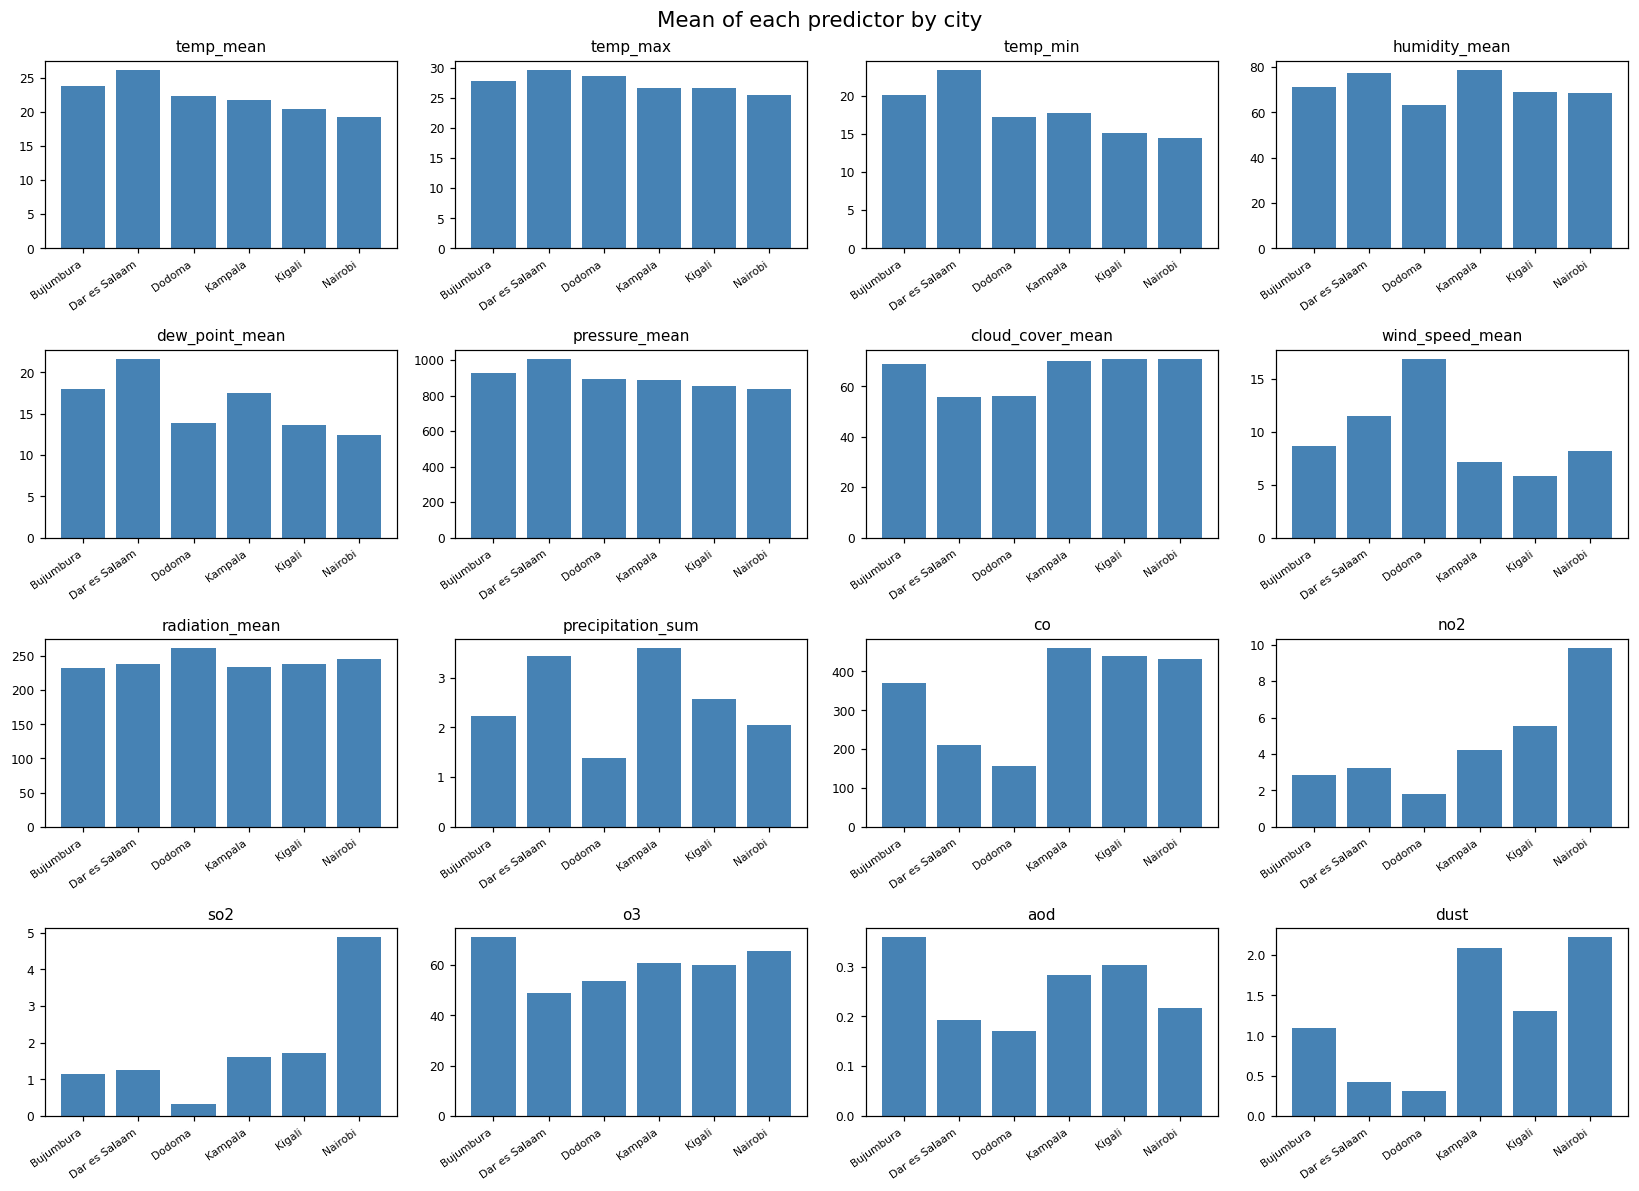

In [13]:
# Work out the mean of each predictor in each city
city_means = df.groupby("city")[predictors_16].mean().reindex(cities)
display(city_means.round(2))

# Draw one panel per predictor in a 4 by 4 grid since the units differ a lot
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
axes = axes.ravel()
for ax, var in zip(axes, predictors_16):
    ax.bar(city_means.index, city_means[var], color="steelblue")
    ax.set_title(var, fontsize=10)
    ax.tick_params(axis="x", rotation=35, labelsize=7)
    ax.tick_params(axis="y", labelsize=8)
    for label in ax.get_xticklabels():
        label.set_ha("right")
fig.suptitle("Mean of each predictor by city", fontsize=14)
plt.tight_layout()
plt.show()

The grid and the accompanying table reveal distinct climatic signatures across the six cities, broadly consistent with geographical expectations. Dar es Salaam, the coastal city, records the highest temp_mean (26.2 degrees), the highest dew point (21.7 degrees) and high humidity (77.2 percent), reflecting moisture laden sea air; its pressure_mean, at approximately 1006.6 hPa, is likewise the highest, consistent with a station near sea level. At the opposite extreme, Nairobi and Kigali are high altitude cities. Nairobi records the lowest pressure (approximately 839.2 hPa) and the lowest temp_mean (19.3 degrees), with Kigali second on both measures; the co-occurrence of reduced pressure and cooler temperatures at altitude is expected on physical grounds.

Precipitation and aridity display the same coherence. Kampala, situated on Lake Victoria, records the highest mean precipitation (3.59 mm per day) and the highest humidity (78.9 percent). Dodoma represents the dry inland case, with the lowest precipitation (1.38 mm), the lowest humidity (63.3 percent), the highest radiation (261.3 units) and the highest wind speed (16.9 units); Kigali records the lowest wind speed (5.8 units). The Dodoma profile is characteristic of a semi arid interior location under comparatively open skies.

Pollutant means are consistent with traffic intensity and urban scale. Nairobi records the highest no2 (9.82) and so2 (4.87), consistent with a large capital city with heavy road traffic, while Kampala records the highest co (459.9), consistent with traffic combined with charcoal and wood smoke in a dense urban setting. Dodoma records the lowest co, no2 and so2, consistent with a smaller urban centre and stronger ventilation. Bujumbura records the highest aod (0.36) and o3 (70.9), while Dodoma records the lowest aod (0.17). The dust mean is highest in Nairobi (2.22) and lowest in Dodoma (0.31); the latter ordering is somewhat counterintuitive given the arid setting of Dodoma, and suggests that the dust variable reflects dry season haze and road dust in the vicinity of the measurement site rather than regional climate alone. Taken as a whole, the means are interpreted as genuine locational signals rather than noise, and imply that a single pooled pollution model would conflate markedly different regimes. City specific modelling is therefore adopted for the remainder of the question.

#### 4.2 What is the correlation between each predictor and the dependent variable (pm2_5), using a separate analysis for each city? Which variable is most relevant for each city, and which variables are relevant in every city? Calculate the correlation between pm10 and pm2_5 in each city. Discuss the advantages and disadvantages of including PM10 as a predictor, considering whether it would be available at prediction time.

,Bujumbura,Dar es Salaam,Dodoma,Kampala,Kigali,Nairobi
temp_mean,0.182,0.256,-0.250,-0.080,0.012,-0.431
temp_max,0.247,0.162,-0.325,0.133,0.042,-0.322
temp_min,0.021,0.260,-0.146,-0.235,0.065,-0.398
humidity_mean,-0.301,-0.071,0.109,-0.025,0.033,0.219
dew_point_mean,-0.279,0.169,-0.002,-0.128,0.049,0.041
pressure_mean,0.051,-0.276,0.042,-0.016,-0.005,0.030
cloud_cover_mean,-0.082,0.091,0.094,0.040,0.140,0.165
wind_speed_mean,0.050,-0.101,-0.375,-0.385,-0.212,-0.512
radiation_mean,-0.064,0.221,-0.156,-0.036,-0.162,-0.421
precipitation_sum,-0.093,-0.096,0.133,-0.062,0.034,0.001


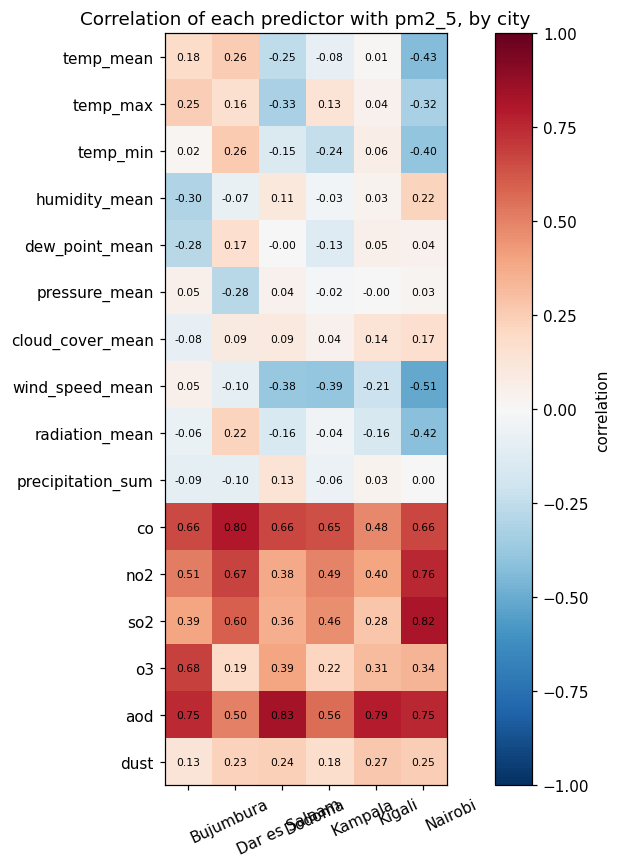

,city,pm10_pm25_correlation,pm2_5_mean
0,Bujumbura,0.928,22.186
1,Dar es Salaam,0.976,9.841
2,Dodoma,0.944,7.640
3,Kampala,0.889,25.667
4,Kigali,0.877,24.262
5,Nairobi,0.951,15.304


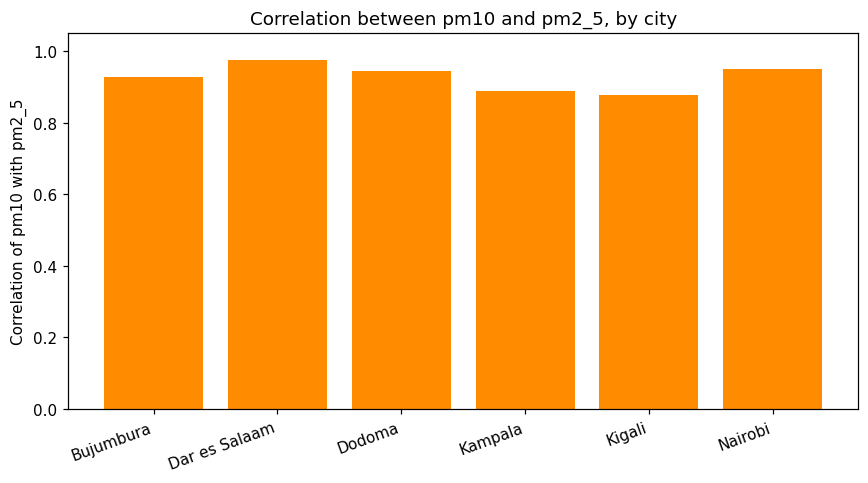

In [14]:
# Work out the correlation of each predictor with pm2_5 in each city
corr_rows = {}
for city in cities:
    sub = df[df["city"] == city]
    corr_rows[city] = sub[predictors_16 + ["pm2_5"]].corr(numeric_only=True)["pm2_5"].drop("pm2_5")
corr_table = pd.DataFrame(corr_rows).reindex(predictors_16)
display(corr_table.round(3))

# Draw the same table as a heat map so strong and weak links stand out
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(corr_table.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cities)))
ax.set_xticklabels(cities, rotation=25, ha="left")
ax.set_yticks(range(len(predictors_16)))
ax.set_yticklabels(predictors_16)
for i in range(len(predictors_16)):
    for j in range(len(cities)):
        ax.text(j, i, f"{corr_table.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Correlation of each predictor with pm2_5, by city")
fig.colorbar(image, ax=ax, label="correlation")
plt.tight_layout()
plt.show()

# Check how tight the link is between pm10 and pm2_5 in each city
pm10_rows = []
for city in cities:
    sub = df[df["city"] == city]
    pm10_rows.append({"city": city,
                      "pm10_pm25_correlation": sub["pm10"].corr(sub["pm2_5"]),
                      "pm2_5_mean": sub["pm2_5"].mean()})
pm10_table = pd.DataFrame(pm10_rows)
display(pm10_table.round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(pm10_table["city"], pm10_table["pm10_pm25_correlation"], color="darkorange")
ax.set_ylabel("Correlation of pm10 with pm2_5")
ax.set_title("Correlation between pm10 and pm2_5, by city")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

The pollutant block carries the association with pm2_5 in every city, whereas most meteorological variables display weak or city specific relationships. The strongest single correlate in Kigali is aod (0.787). In Nairobi the strongest is so2 (0.819), with no2 (0.756) and aod (0.752) close behind. In Kampala the strongest is co (0.648). In Dodoma the strongest is aod (0.832), the largest value in the table. In Bujumbura the strongest is aod (0.747), followed by o3 (0.681), while in Dar es Salaam the strongest is co (0.798). Aerosol optical depth therefore leads in three cities and a traffic related gas in the remaining three. The pattern is substantively plausible: aod measures the column particle burden remotely, while co, no2 and so2 are co-emitted with fine particles by traffic and combustion sources, so both groups trace the same smoke and exhaust mixture.

Only three variables exceed the $|r| > 0.3$ threshold in all six cities, namely co, no2 and aod, and these are accordingly designated relevant in every city. So2 exceeds the threshold in five cities, falling just short in Kigali (0.275), and o3 in four. Wind speed is the sole meteorological variable with a material association, and it is negative where it matters (Nairobi minus 0.512, Kampala minus 0.385, Dodoma minus 0.375), consistent with ventilation dispersing particles. In Bujumbura and Dar es Salaam the wind association is close to zero, plausibly because lake and sea breezes both disperse and transport air in a less directional manner. Same day precipitation displays almost no linear association with pm2_5, indicating that washout effects are weak at the daily mean scale, or that wet days combine hours of low and high particle concentration.

The association between pm10 and pm2_5 is very strong in every city, ranging from 0.877 in Kigali to 0.976 in Dar es Salaam. This is unsurprising, since pm10 mass incorporates the fine fraction together with a coarse fraction, and the two series share sources and meteorological drivers. Inclusion of pm10 as a predictor would undoubtedly raise fit substantially, as it is close to a partial copy of the target. The disadvantages, however, are decisive. Inclusion would approach leakage, in that pm2_5 would in part be predicted from a measurement already containing pm2_5 mass; the variable would dominate the specification and obscure the drivers of pollution; and, most importantly for deployment, same day pm10 is unavailable at the time an advance forecast for that day is required, being available only for nowcasting where a pm10 sensor reports in real time. Since the specified predictor set of 16 variables excludes pm10 and the objective is a usable forecast, pm10 is excluded.

#### 4.3 For each city, standardize the predictors and use Lasso and cross-validation(10 folds) to provide a plot of MSE against lambda (Estimate the standardization parameters using training data only). How many predictors does the best Lasso model keep in each city, and how do the features selected compare with an approach of setting a threshold on the absolute correlation coefficient(|r| > 0.3)?

A terminological note is required. The question denotes the penalty by lambda, whereas the Lasso implementation employed here denotes the same quantity by alpha. Lambda is used in the text and figures, and the value is passed to the model through its alpha argument. Within every cross-validation fold, the scaler is estimated on the training partition only and applied to the test partition by means of a pipeline, ensuring that no test observation influences the scaling.

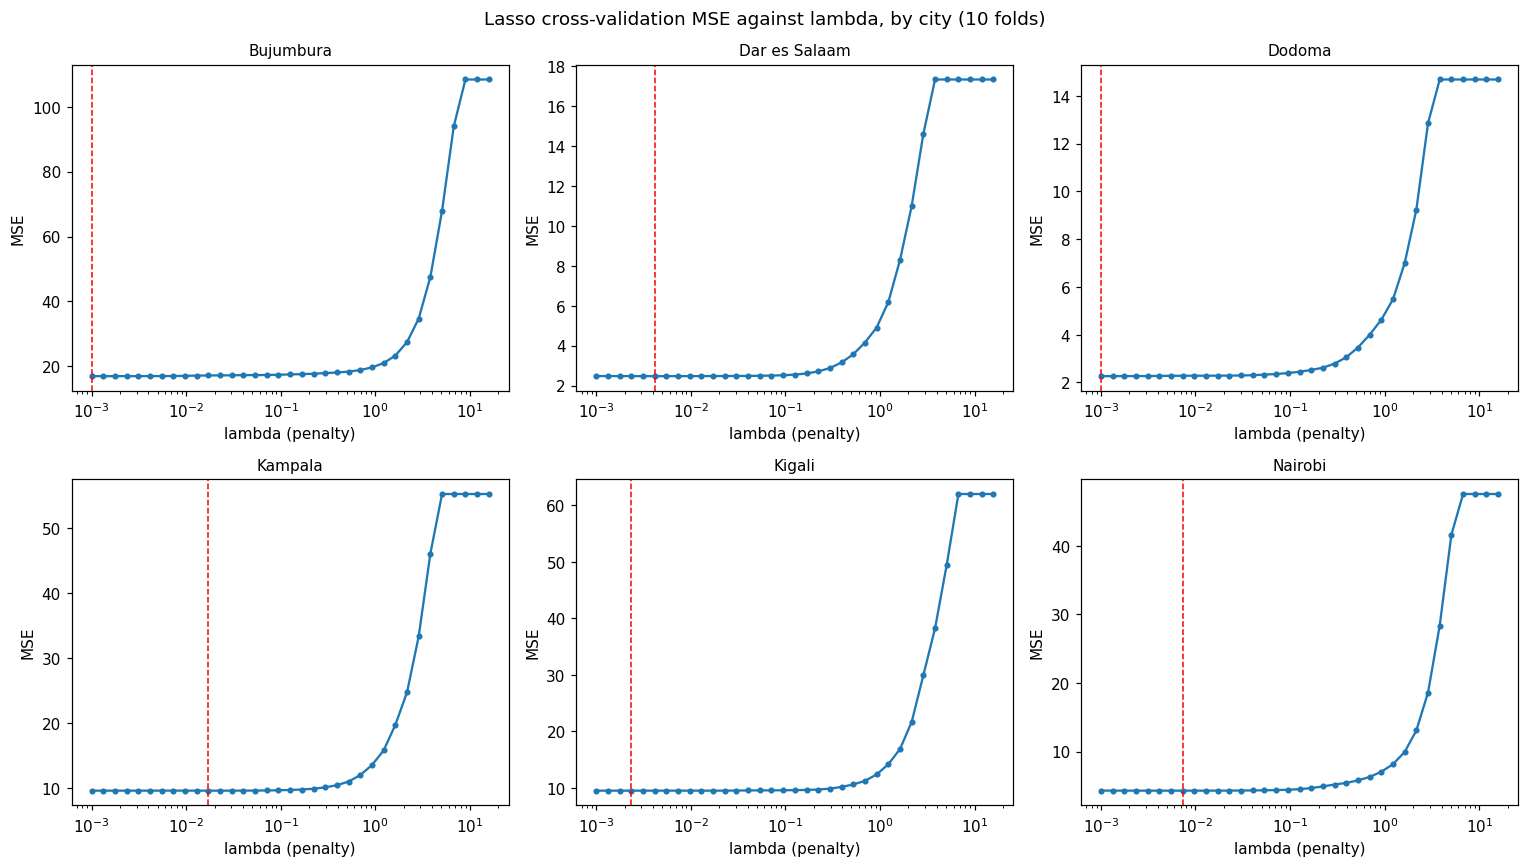

,city,best_lambda,best_cv_mse,kept_count,kept_predictors
0,Bujumbura,0.0010,16.9857,16,"temp_mean, temp_max, temp_min, humidity_mean, ..."
1,Dar es Salaam,0.0041,2.4686,13,"temp_max, temp_min, humidity_mean, pressure_me..."
2,Dodoma,0.0010,2.2617,16,"temp_mean, temp_max, temp_min, humidity_mean, ..."
3,Kampala,0.0172,9.5530,14,"temp_max, temp_min, dew_point_mean, pressure_m..."
4,Kigali,0.0023,9.5408,16,"temp_mean, temp_max, temp_min, humidity_mean, ..."
5,Nairobi,0.0073,4.2903,14,"temp_max, temp_min, dew_point_mean, pressure_m..."


In [15]:
# Scan the Lasso penalty for each city and I record the cross-validation MSE at each value
cv_reg = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
lambda_grid = np.logspace(-3, 1.2, 35)
lasso_curves = {}
lasso_selected = {}
lasso_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for ax, city in zip(axes, cities):
    sub = df[df["city"] == city].dropna(subset=["pm2_5"] + predictors_16)
    X_city = sub[predictors_16]
    y_city = sub["pm2_5"]
    mean_mses = []
    for lam in lambda_grid:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("model", Lasso(alpha=lam, max_iter=10000))])
        neg_scores = cross_val_score(pipe, X_city, y_city, cv=cv_reg, scoring="neg_mean_squared_error")
        mean_mses.append(-neg_scores.mean())
    mean_mses = np.array(mean_mses)
    lasso_curves[city] = mean_mses
    best_pos = int(np.argmin(mean_mses))
    best_lambda = float(lambda_grid[best_pos])
    # Refit at the best penalty on the full city data to see which predictors stay
    full_pipe = Pipeline([("scaler", StandardScaler()),
                          ("model", Lasso(alpha=best_lambda, max_iter=10000))])
    full_pipe.fit(X_city, y_city)
    coefs = full_pipe.named_steps["model"].coef_
    kept = [var for var, c in zip(predictors_16, coefs) if abs(c) > 1e-8]
    lasso_selected[city] = kept
    lasso_rows.append({"city": city, "best_lambda": best_lambda, "best_cv_mse": mean_mses[best_pos],
                       "kept_count": len(kept), "kept_predictors": ", ".join(kept)})
    ax.plot(lambda_grid, mean_mses, marker="o", markersize=3)
    ax.axvline(best_lambda, color="red", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_title(city, fontsize=10)
    ax.set_xlabel("lambda (penalty)")
    ax.set_ylabel("MSE")
fig.suptitle("Lasso cross-validation MSE against lambda, by city (10 folds)")
plt.tight_layout()
plt.show()
lasso_table = pd.DataFrame(lasso_rows)
display(lasso_table.round(4))

In [16]:
# Set the correlation threshold sets next to the Lasso sets so the two can be compared
compare_sets = []
for city in cities:
    corr_set = [var for var in predictors_16 if abs(corr_table.loc[var, city]) > 0.3]
    lasso_set = lasso_selected[city]
    compare_sets.append({"city": city,
                         "corr_threshold_count": len(corr_set),
                         "corr_threshold_set": ", ".join(corr_set),
                         "lasso_count": len(lasso_set),
                         "shared_count": len(set(corr_set) & set(lasso_set)),
                         "only_in_lasso": ", ".join(sorted(set(lasso_set) - set(corr_set)))})
display(pd.DataFrame(compare_sets))

,city,corr_threshold_count,corr_threshold_set,lasso_count,shared_count,only_in_lasso
0,Bujumbura,6,"humidity_mean, co, no2, so2, o3, aod",16,6,"cloud_cover_mean, dew_point_mean, dust, precip..."
1,Dar es Salaam,4,"co, no2, so2, aod",13,4,"dust, humidity_mean, o3, precipitation_sum, pr..."
2,Dodoma,7,"temp_max, wind_speed_mean, co, no2, so2, o3, aod",16,7,"cloud_cover_mean, dew_point_mean, dust, humidi..."
3,Kampala,5,"wind_speed_mean, co, no2, so2, aod",14,5,"cloud_cover_mean, dew_point_mean, dust, o3, pr..."
4,Kigali,4,"co, no2, o3, aod",16,4,"cloud_cover_mean, dew_point_mean, dust, humidi..."
5,Nairobi,10,"temp_mean, temp_max, temp_min, wind_speed_mean...",14,9,"cloud_cover_mean, dew_point_mean, dust, precip..."


The MSE curves exhibit a common shape across the six cities. At large values of lambda the penalty dominates, coefficients are heavily shrunk and MSE is high; as lambda decreases, MSE falls rapidly before settling onto an extended flat region, with at most a marginal increase at the extreme left of the grid. The optimal lambda is small in every city. At that optimum, Lasso retains almost all predictors: all 16 in Kigali, 14 in Nairobi, 14 in Kampala, all 16 in Dodoma, all 16 in Bujumbura and 13 in Dar es Salaam. Exact values, together with the retained variable lists, are reported in the table above.

The correlation threshold produces a markedly stricter selection, retaining 4 predictors in Kigali, 10 in Nairobi, 5 in Kampala, 7 in Dodoma, 6 in Bujumbura and 4 in Dar es Salaam. Nearly every variable retained by the threshold rule is also retained by Lasso, so the Lasso set is close to a superset of the threshold set. The discrepancy arises from variables whose marginal linear association is weak but which contribute conditionally once the principal pollutants are included, together with instances in which correlated variables share the predictive load and are both retained with small coefficients.

Two implications follow. First, with approximately 1,518 observations per city, the MSE optimal penalty is weak, because the data support many small coefficients; Lasso at its optimum therefore performs light trimming rather than aggressive selection. Its contribution in this setting is stabilisation of the coefficient estimates and confirmation that nearly all 16 predictors carry some signal. Second, the $|r| > 0.3$ rule is not an equivalent procedure: it is a marginal screen that disregards joint behaviour and consequently discards variables that are useful in combination. Where a short predictor list is desired in its own right, either the threshold list or a larger lambda beyond the flat region would supply it, at the modest MSE cost made visible by the flat curves.

#### 4.4 For each city, use the features identified by LASSO, standardize them, construct a KNN regression model, and choose the best number of neighbors by cross-validation of 10 folds.

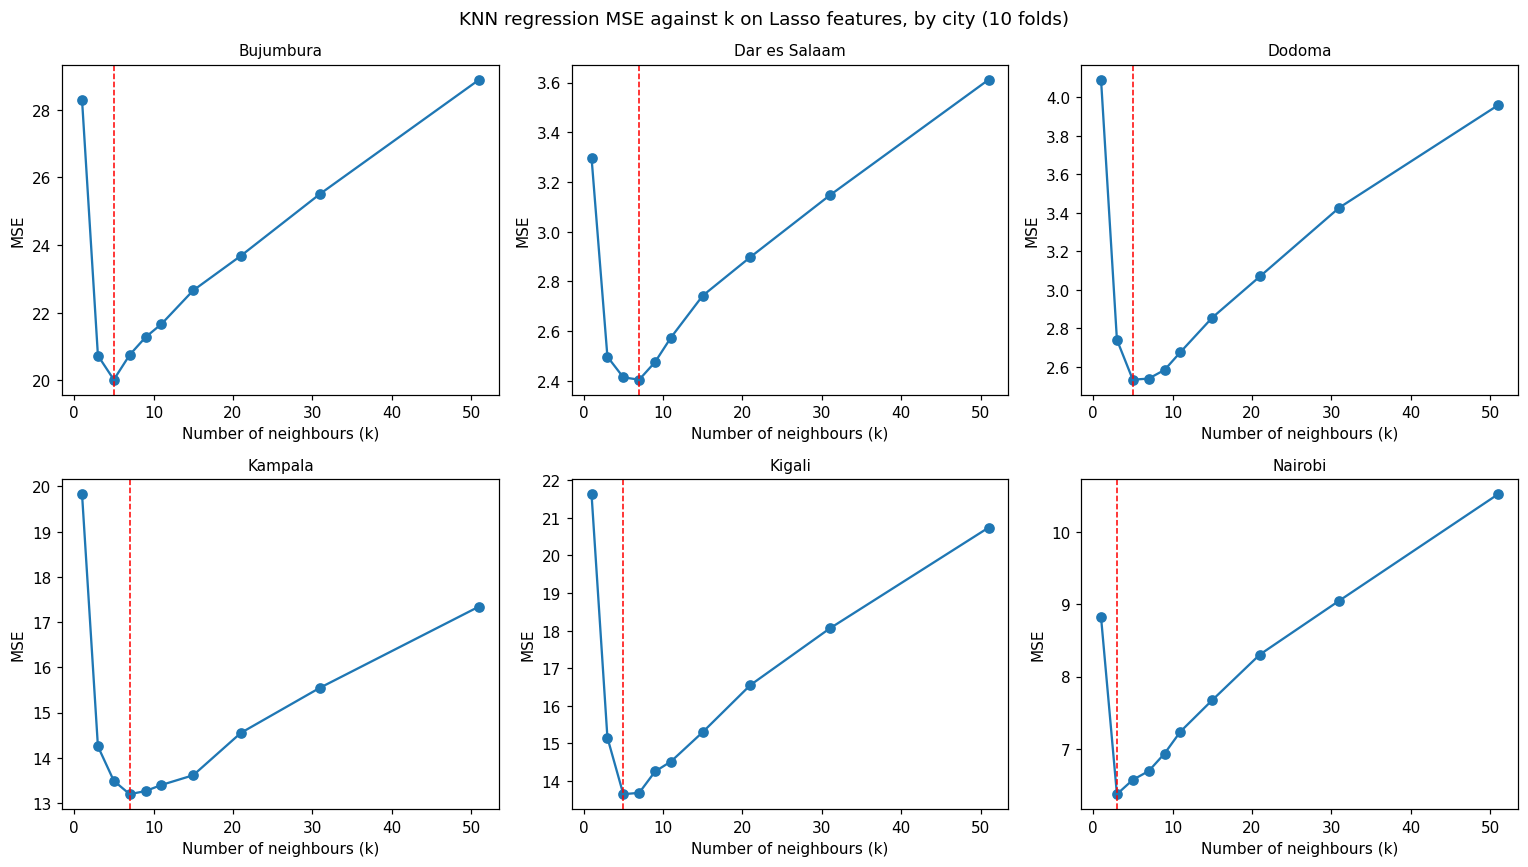

,city,features_used,best_k,cv_mse,cv_r2
0,Bujumbura,16,5,20.0224,0.8122
1,Dar es Salaam,13,7,2.4049,0.8602
2,Dodoma,16,5,2.5321,0.8197
3,Kampala,14,7,13.1953,0.7583
4,Kigali,16,5,13.6479,0.7769
5,Nairobi,14,3,6.3764,0.8614


In [17]:
# Tune the neighbourhood size for KNN regression on the Lasso features of each city
k_reg_list = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]
knn_lasso_best = {}
knn_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for ax, city in zip(axes, cities):
    sub = df[df["city"] == city].dropna(subset=["pm2_5"] + predictors_16)
    feats = lasso_selected[city]
    X_city = sub[feats]
    y_city = sub["pm2_5"]
    mses = []
    r2s = []
    for k in k_reg_list:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("model", KNeighborsRegressor(n_neighbors=k))])
        scores = cross_validate(pipe, X_city, y_city, cv=cv_reg,
                                scoring=["neg_mean_squared_error", "r2"])
        mses.append(-scores["test_neg_mean_squared_error"].mean())
        r2s.append(scores["test_r2"].mean())
    best_pos = int(np.argmin(mses))
    knn_lasso_best[city] = k_reg_list[best_pos]
    knn_rows.append({"city": city, "features_used": len(feats), "best_k": k_reg_list[best_pos],
                     "cv_mse": mses[best_pos], "cv_r2": r2s[best_pos]})
    ax.plot(k_reg_list, mses, marker="o")
    ax.axvline(k_reg_list[best_pos], color="red", linestyle="--", linewidth=1)
    ax.set_title(city, fontsize=10)
    ax.set_xlabel("Number of neighbours (k)")
    ax.set_ylabel("MSE")
fig.suptitle("KNN regression MSE against k on Lasso features, by city (10 folds)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(knn_rows).round(4))

The optimal neighbourhood sizes for regression are considerably smaller than the values near 100 selected for the rainfall classification task. Optimal $k$ values fall in single digits for most cities, approximately 3 to 9. The MSE curves decline sharply from $k = 1$, attain a well defined minimum, and subsequently rise slowly as larger neighbourhoods average over dissimilar atmospheric states. The contrast with classification is explicable: estimation of a continuous outcome is served by the mean of a tightly defined group of comparable days, whereas stabilisation of a noisy binary classification required aggregation over a much larger vote.

Fit is strong throughout, with $R^2$ values between approximately 0.76 and 0.86; city level detail is reported in the table. Nairobi and Dar es Salaam attain the highest proportions of explained variance, while Bujumbura exhibits the largest absolute MSE, consistent with its more variable pm2_5 levels. These estimates employ Lasso variable lists selected on the full city samples, and may therefore contain a small element of selection optimism. That element is removed in the following section, where selection is repeated inside each training fold.

#### 4.5 For each city, how does KNN with all the predictors perform compared to KNN with the LASSO-selected features, measured by MSE and R2 with cross-validation of 10 folds, and in which cities is the difference largest? (Perform feature selection, standardization, and hyperparameter tuning within each fold's training data)

,city,mse_all,r2_all,mse_lasso,r2_lasso,mse_gain_lasso
0,Bujumbura,20.2312,0.8106,20.3517,0.8096,-0.1205
1,Dar es Salaam,2.5598,0.8510,2.4382,0.8583,0.1217
2,Dodoma,2.5770,0.8164,2.5354,0.8186,0.0416
3,Kampala,14.0336,0.7414,13.6201,0.7505,0.4135
4,Kigali,13.6479,0.7769,13.7509,0.7752,-0.1030
5,Nairobi,6.8731,0.8521,6.7838,0.8527,0.0893


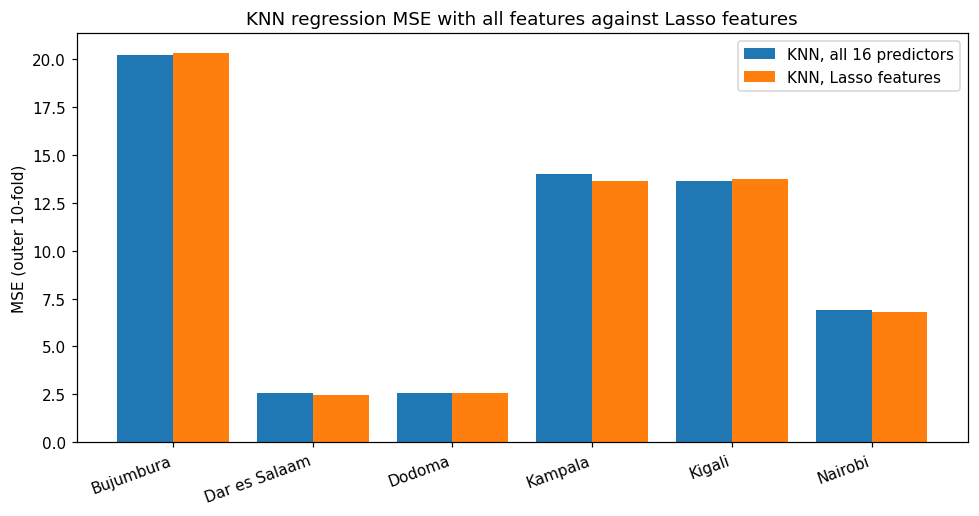

In [18]:
# Compare two KNN routes with an outer 10-fold loop and all tuning done inside each training part
inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_lambdas = np.logspace(-3, 1.0, 16)
k_inner = [1, 3, 5, 7, 9, 11, 15, 21]

def pick_lasso_features(X_train, y_train):
    # Choose the penalty by inner cross-validation, then I read the kept names at that penalty
    best_lambda = inner_lambdas[0]
    best_mse = None
    for lam in inner_lambdas:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("model", Lasso(alpha=lam, max_iter=10000))])
        neg_scores = cross_val_score(pipe, X_train, y_train, cv=inner_cv, scoring="neg_mean_squared_error")
        mse = -neg_scores.mean()
        if best_mse is None or mse < best_mse:
            best_mse = mse
            best_lambda = lam
    scaler = StandardScaler().fit(X_train)
    model = Lasso(alpha=best_lambda, max_iter=10000).fit(scaler.transform(X_train), y_train)
    kept = [var for var, c in zip(X_train.columns, model.coef_) if abs(c) > 1e-8]
    if len(kept) == 0:
        kept = list(X_train.columns)
    return kept

def pick_best_k(X_train, y_train, cols):
    # Choose k by inner cross-validation with the scaler fit inside each inner fold
    best_k = k_inner[0]
    best_mse = None
    for k in k_inner:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("model", KNeighborsRegressor(n_neighbors=k))])
        neg_scores = cross_val_score(pipe, X_train[cols], y_train, cv=inner_cv, scoring="neg_mean_squared_error")
        mse = -neg_scores.mean()
        if best_mse is None or mse < best_mse:
            best_mse = mse
            best_k = k
    return best_k

nested_rows = []
for city in cities:
    sub = df[df["city"] == city].dropna(subset=["pm2_5"] + predictors_16).reset_index(drop=True)
    X_city = sub[predictors_16]
    y_city = sub["pm2_5"].values
    fold_mse_all, fold_r2_all, fold_mse_lasso, fold_r2_lasso = [], [], [], []
    for train_idx, test_idx in cv_reg.split(X_city, y_city):
        X_train = X_city.iloc[train_idx]
        y_train = y_city[train_idx]
        X_test = X_city.iloc[test_idx]
        y_test = y_city[test_idx]
        # Route one: all 16 predictors, with k tuned inside this training part
        k_all = pick_best_k(X_train, pd.Series(y_train), predictors_16)
        scaler_all = StandardScaler().fit(X_train[predictors_16])
        model_all = KNeighborsRegressor(n_neighbors=k_all).fit(scaler_all.transform(X_train[predictors_16]), y_train)
        pred_all = model_all.predict(scaler_all.transform(X_test[predictors_16]))
        fold_mse_all.append(mean_squared_error(y_test, pred_all))
        fold_r2_all.append(r2_score(y_test, pred_all))
        # Route two: Lasso picks the features inside this training part, then k is tuned the same way
        feats = pick_lasso_features(X_train, pd.Series(y_train))
        k_las = pick_best_k(X_train, pd.Series(y_train), feats)
        scaler_las = StandardScaler().fit(X_train[feats])
        model_las = KNeighborsRegressor(n_neighbors=k_las).fit(scaler_las.transform(X_train[feats]), y_train)
        pred_las = model_las.predict(scaler_las.transform(X_test[feats]))
        fold_mse_lasso.append(mean_squared_error(y_test, pred_las))
        fold_r2_lasso.append(r2_score(y_test, pred_las))
    nested_rows.append({"city": city,
                        "mse_all": np.mean(fold_mse_all), "r2_all": np.mean(fold_r2_all),
                        "mse_lasso": np.mean(fold_mse_lasso), "r2_lasso": np.mean(fold_r2_lasso)})
nested_table = pd.DataFrame(nested_rows)
nested_table["mse_gain_lasso"] = nested_table["mse_all"] - nested_table["mse_lasso"]
display(nested_table.round(4))

# Draw the MSE of the two routes side by side for each city
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(nested_table))
ax.bar(x - 0.2, nested_table["mse_all"], width=0.4, label="KNN, all 16 predictors")
ax.bar(x + 0.2, nested_table["mse_lasso"], width=0.4, label="KNN, Lasso features")
ax.set_xticks(x)
ax.set_xticklabels(nested_table["city"], rotation=20, ha="right")
ax.set_ylabel("MSE (outer 10-fold)")
ax.set_title("KNN regression MSE with all features against Lasso features")
ax.legend()
plt.tight_layout()
plt.show()

When variable selection, standardisation and $k$ tuning are all repeated within each training fold, the two routes produce closely similar performance. The result follows directly from Section 4.3: at its MSE optimum Lasso retains between 13 and 16 of the 16 predictors, so the Lasso based route differs only marginally from the full predictor route by construction. In Dodoma and Bujumbura the routes largely coincide across folds, Lasso retaining all 16 predictors in those cities. Where trimming does occur, as in Kampala and Dar es Salaam, the reduced route attains a small advantage, with MSE falling and $R^2$ rising slightly, because distance calculations are disproportionately degraded by coordinates that contribute dispersion without signal. Kampala displays the largest difference, an MSE improvement of approximately 0.41, followed by Dar es Salaam at approximately 0.12. In Kigali and Bujumbura the Lasso route is marginally worse, by approximately 0.10 MSE, so the advantage is small and not universal; even the largest difference is minor relative to the level of MSE within each city.

The overall assessment is that Lasso screening is harmless in this application and secures a more parsimonious and stable distance space at negligible cost. It does not, however, deliver a substantial performance gain, because the discarded predictors were largely innocuous after standardisation and the retained set continues to contain the correlated pollutant block that drives pm2_5. Where predictive accuracy is the sole objective, the Lasso feature KNN is preferred in cities where trimming occurs, on the basis of a small and consistent advantage. Where a short sensor list is the objective, neither route supplies it, since the optimal Lasso is inclusive; a larger lambda along the flat region of Section 4.3 would then be required, accepting the modest MSE increase there displayed as the price of parsimony.